> **EDA cells for Jupyter Notebook - Vietnamese Legal Documents.**
> All heavy logic lives in `eda.py`, notebook only calls + displays.
>
> Convert: `jupytext --to notebook eda-ipynb.py -o eda.ipynb`

# EDA - Vietnamese Legal Documents (Parquet)

## Cấu trúc Dataset
Dataset gồm 4 cấu hình (configs):

| Config | Split | Dòng | Mô tả |
|---|---|---|---|
| `metadata` | `data` | 153,420 | Mỗi văn bản một dòng - 16 trường metadata |
| `content` | `data` | 178,665 | Nội dung toàn văn gốc định dạng HTML |
| `relationships` | `data` | 897,890 | Đồ thị có hướng (edges) giữa các văn bản |
| `legacy` | `metadata` | 518,601 | Lần cào cũ hơn - Tên trường tiếng Anh |
| `legacy` | `content` | 518,235 | Nội dung text thuần cho dữ liệu cũ |

### 1. data / metadata
| Cột | Mô tả |
|---|---|
| `id` | ID định danh văn bản (int) |
| `title` | Tiêu đề đầy đủ tiếng Việt |
| `so_ky_hieu` | Số hiệu chính thức, VD: 115/NQ-HĐBCQG |
| `ngay_ban_hanh` | Ngày ban hành (DD/MM/YYYY) |
| `loai_van_ban` | Loại văn bản - Quyết định, Nghị quyết, Thông tư, … |
| `ngay_co_hieu_luc` | Ngày có hiệu lực |
| `ngay_het_hieu_luc` | Ngày hết hiệu lực (rỗng nếu còn hiệu lực) |
| `nguon_thu_thap` | Nguồn thu thập (VD: Công báo) |
| `ngay_dang_cong_bao` | Ngày đăng Công báo |
| `nganh` | Ngành - Tài chính, Y tế, … |
| `linh_vuc` | Lĩnh vực pháp lý |
| `co_quan_ban_hanh` | Cơ quan ban hành (551 cơ quan) |
| `chuc_danh` | Chức danh người ký - Chủ tịch, Bộ trưởng, … |
| `nguoi_ky` | Tên người ký |
| `pham_vi` | Phạm vi áp dụng |
| `thong_tin_ap_dung` | Thông tin áp dụng |
| `tinh_trang_hieu_luc` | Tình trạng hiệu lực - Còn hiệu lực, Hết hiệu lực toàn bộ, … |

### 2. data / content
| Cột | Mô tả |
|---|---|
| `id` | ID văn bản (join key → metadata.id) |
| `content_html` | Nội dung văn bản định dạng HTML gốc |
*Lưu ý: Một số văn bản trong metadata không có dữ liệu trong content vì cổng thông tin chỉ cung cấp bản scan PDF cho các văn bản đó (không có bản HTML).*

### 3. data / relationships
| Cột | Mô tả |
|---|---|
| `doc_id` | ID văn bản nguồn (join key → metadata.id) |
| `other_doc_id` | ID văn bản đích |
| `relationship` | Loại quan hệ (Căn cứ, Hướng dẫn, v.v.) |

### 4. legacy (metadata & content)
Một bản snapshot cào cũ hơn với khoảng 518 nghìn văn bản. Tên cột và các giá trị tiếng Anh (khác với data sử dụng tiếng Việt). Ngày tháng ở định dạng YYYY-MM-DD.
Nên sử dụng config này khi cần độ bao phủ lớn hơn nhưng phải hy sinh sự phong phú của metadata.

**legacy / metadata (518,601 dòng):**
| Cột | Mô tả |
|---|---|
| `id` | ID định danh văn bản (int) |
| `document_number` | Số hiệu chính thức |
| `title` | Tiêu đề đầy đủ tiếng Việt |
| `legal_type` | Loại văn bản tiếng Anh - Resolution, Decision, Circular, … |
| `legal_sectors` | Lĩnh vực tiếng Anh - Finance, Education, … |
| `issuing_authority` | Cơ quan ban hành (tên tiếng Việt) |
| `issuance_date` | Ngày ban hành (YYYY-MM-DD) |
| `effect_date` | Ngày hiệu lực (YYYY-MM-DD) |
| `effectless_date` | Ngày hết hiệu lực |
| `effect_status` | Tình trạng hiệu lực |
| `signers` | Người ký và ID |

**legacy / content (518,235 dòng):**
| Cột | Mô tả |
|---|---|
| `id` | ID văn bản (join key → legacy/metadata.id) |
| `content` | Nội dung text thuần (không phải HTML) |

In [1]:
# === Cell 1: Imports & Config ===
# Auto-reload eda.py khi file thay đổi (không cần restart kernel)
# noinspection PyUnresolvedReferences
%load_ext autoreload
# noinspection PyUnresolvedReferences
%autoreload 2

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import os
from IPython.display import display, Markdown

# Import hàm từ eda.py
from eda import (
    compute_column_stats,
    get_label_value_counts,
    compare_content_datasets,
    compare_metadata_datasets,
    get_id_coverage,
)

# Polars config
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(120)  # Truncate long strings in head displays
pl.Config.set_tbl_width_chars(500)
pl.Config.set_tbl_cols(20)

# Matplotlib config – clean style matching figure
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
sns.set_theme(style="ticks", palette="muted", font_scale=1.1)

# Resolve project root (2 levels up from pipeline/02_eda/)
# Works as .py script (__file__ exists) and as .ipynb (falls back to cwd)
try:
    _THIS_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _THIS_DIR = os.getcwd()
_PROJECT_ROOT = os.path.dirname(os.path.dirname(_THIS_DIR))
BASE = os.path.join(_PROJECT_ROOT, "data", "raw", "vietnamese-legal-documents")
FILES = {
    "data/content":       os.path.join(BASE, "data", "content.parquet"),
    "data/metadata":      os.path.join(BASE, "data", "metadata.parquet"),
    "data/relationships": os.path.join(BASE, "data", "relationships.parquet"),
    "legacy/content":     os.path.join(BASE, "legacy", "content.parquet"),
    "legacy/metadata":    os.path.join(BASE, "legacy", "metadata.parquet"),
}

# Tổng quan file
overview_rows = []
for name, path in FILES.items():
    exists = os.path.exists(path)
    size_mb = round(os.path.getsize(path) / 1e6, 1) if exists else 0
    schema = pl.scan_parquet(path).collect_schema() if exists else None
    num_rows = pl.scan_parquet(path).select(pl.len()).collect().item() if exists else 0
    overview_rows.append({
        "file": name,
        "size_MB": size_mb,
        "rows": f"{num_rows:,}" if exists else "N/A",
        "columns": ", ".join(schema.names()) if schema else "N/A",
    })
display(Markdown("### 📂 Tổng quan Dataset"))
display(pl.DataFrame(overview_rows))

### 📂 Tổng quan Dataset

file,size_MB,rows,columns
str,f64,str,str
"""data/content""",411.8,"""178,665""","""id, content_html"""
"""data/metadata""",14.1,"""153,420""","""id, title, so_ky_hieu, ngay_ban_hanh, loai_van_ban, ngay_co_hieu_luc, ngay_het_hieu_luc, nguon_thu_thap, ngay_dang_cong_…"
"""data/relationships""",4.1,"""897,890""","""doc_id, other_doc_id, relationship"""
"""legacy/content""",3507.7,"""518,235""","""id, content"""
"""legacy/metadata""",51.3,"""518,601""","""id, document_number, title, legal_type, legal_sectors, issuing_authority, issuance_date, effect_date, effectless_date, e…"


---
## 1. Schema
Hầu hết các cột là **String**. Dưới đây chỉ liệt kê các cột **không phải String**:

In [2]:
# === Cell 2: Schema – chỉ hiện cột non-String ===
for name, path in FILES.items():
    if not os.path.exists(path):
        continue
    schema = pl.scan_parquet(path).collect_schema()
    non_str = {col: str(dtype) for col, dtype in schema.items() if dtype != pl.String}
    if non_str:
        detail = ", ".join(f"{c} ({t})" for c, t in non_str.items())
    else:
        detail = "(tất cả String)"
    display(Markdown(f"**📄 {name}** — {len(schema)} cột — non-String: {detail}"))

**📄 data/content** — 2 cột — non-String: (tất cả String)

**📄 data/metadata** — 17 cột — non-String: id (Int64), thong_tin_ap_dung (Float64)

**📄 data/relationships** — 3 cột — non-String: doc_id (Int64), other_doc_id (Int64)

**📄 legacy/content** — 2 cột — non-String: id (Int64)

**📄 legacy/metadata** — 11 cột — non-String: id (Int64)

---
## 2. Head - Xem mẫu dữ liệu
Dùng `.to_pandas()` để Jupyter hiện đầy đủ nội dung cột dài (title, content).

In [3]:
# === Cell 3: Head - data/content ===
# Note: content_html contains raw HTML tags – that's the original format
display(Markdown("### 📄 data/content"))
display(
    pl.scan_parquet(FILES["data/content"]).head(3).collect()
    .with_columns(pl.col("content_html").str.slice(0, 200).alias("content_html"))
)

### 📄 data/content

id,content_html
str,str
"""4260""","""<table class=""detailcontent"" width=""100%"" border=""0"" id=""content""> <tr> <td colspa…"
"""4266""","""<table class=""detailcontent"" width=""100%"" border=""0"" id=""content""> <tr> <td colspa…"
"""4262""","""<table class=""detailcontent"" width=""100%"" border=""0"" id=""content""> <tr> <td colspa…"


In [4]:
# === Cell 4: Head - data/metadata ===
display(Markdown("### 📄 data/metadata"))
_df4 = pl.scan_parquet(FILES["data/metadata"]).head(3).collect().to_pandas()
from IPython.display import HTML
display(HTML(
    _df4.style
    .set_properties(**{"white-space": "nowrap"})  # no wrapping on all cols
    .set_properties(subset=["title"], **{"white-space": "normal", "min-width": "400px", "max-width": "600px"})
    .set_table_styles([{"selector": "table", "props": [("width", "100%")]}])
    .to_html()
))

### 📄 data/metadata

,id,title,so_ky_hieu,ngay_ban_hanh,loai_van_ban,ngay_co_hieu_luc,ngay_het_hieu_luc,nguon_thu_thap,ngay_dang_cong_bao,nganh,linh_vuc,co_quan_ban_hanh,chuc_danh,nguoi_ky,pham_vi,thong_tin_ap_dung,tinh_trang_hieu_luc
0,72,Sắc lệnh quy định liên hệ giữa UBKCHC và các cơ quan chuyên môn,103/SL,05/06/1950,Sắc lệnh,20/06/1950,nan,Công báo số 7/1950;,...,nan,nan,Chủ tịch nước,Chủ tịch nước,Hồ Chí Minh,nan,nan,Hết hiệu lực toàn bộ
1,4260,Về việc chuyển giao nhiệm vụ quản lý Nhà nước về đất lâm nghiệp từ Sở Nông nghiệp và Phát triển Nông thôn và Chi cục kiểm lâm tỉnh sang Sở Địa chính để quản lý,87/1999/QĐ-UB,12/07/1999,Quyết định,12/07/1999,nan,STP tỉnh Lâm Đồng;,...,nan,nan,UBND tỉnh Lâm Đồng,Q.Chủ tịch,Đặng Đức Lợi,Lâm Đồng,nan,Còn hiệu lực
2,4280,Về viẹc quản lý và quy định thống nhất phí chợ trên địa bàn tỉnh Lâm Đồng,157/1999/QĐ-UB,19/11/1999,Quyết định,19/11/1999,nan,STP tỉnh Lâm Đồng;,...,Tài chính,nan,UBND tỉnh Lâm Đồng,Phó Chủ tịch,Trương Thành Trung,Lâm Đồng,nan,Còn hiệu lực


In [5]:
# === Cell 5: Head - data/relationships ===
display(Markdown("### 📄 data/relationships"))
display(pl.scan_parquet(FILES["data/relationships"]).head(5).collect())

### 📄 data/relationships

doc_id,other_doc_id,relationship
i64,i64,str
4260,10420,"""Văn bản căn cứ"""
4280,7245,"""Văn bản căn cứ"""
4263,10420,"""Văn bản căn cứ"""
77,195,"""Văn bản hết hiệu lực"""
77,65,"""Văn bản bổ sung"""


In [6]:
# === Cell 6: Head - legacy/content ===
display(Markdown("### 📄 legacy/content"))
display(pl.scan_parquet(FILES["legacy/content"]).head(3).collect())

### 📄 legacy/content

id,content
i64,str
693036,"""HỘI ĐỒNG BẦU CỬ QUỐC GIA | CỘNG HÒA XÃ HỘI CHỦ NGHĨA VIỆT NAM Độc lập - Tự do - Hạnh phúc Số: 115/NQ-HĐBCQG | Hà Nội, …"
680604,"""ỦY BAN NHÂN DÂN TỈNH QUẢNG TRỊ | CỘNG HÒA XÃ HỘI CHỦ NGHĨA VIỆT NAM Độc lập - Tự do - Hạnh phúc Số: 34/2025/QĐ-UBND | …"
694312,"""ỦY BAN NHÂN DÂN THÀNH PHỐ HỒ CHÍ MINH | CỘNG HÒA XÃ HỘI CHỦ NGHĨA VIỆT NAM Độc lập - Tự do - Hạnh phúc Số: 06/2026/QĐ-…"


In [7]:
# === Cell 7: Head - legacy/metadata ===
display(Markdown("### 📄 legacy/metadata"))
_df7 = pl.scan_parquet(FILES["legacy/metadata"]).head(3).collect().to_pandas()
display(HTML(
    _df7.style
    .set_properties(**{"white-space": "nowrap"})
    .set_properties(subset=["title"], **{"white-space": "normal", "min-width": "400px", "max-width": "600px"})
    .set_table_styles([{"selector": "table", "props": [("width", "100%")]}])
    .to_html()
))

### 📄 legacy/metadata

,id,document_number,title,legal_type,legal_sectors,issuing_authority,issuance_date,effect_date,effectless_date,effect_status,signers
0,693036,115/NQ-HĐBCQG,Nghị quyết 115/NQ-HĐBCQG năm 2026 hướng dẫn xử lý trường hợp khuyết người ứng cử đại biểu Hội đồng nhân dân vì lý do bất khả kháng do Hội đồng bầu cử Quốc gia ban hành,Resolution,Administrative apparatus,Hội đồng bầu cử quốc gia,2026-01-29,2026-01-29,nan,In effect,Trần Thanh Mẫn:2140
1,680604,34/2025/QĐ-UBND,"Quyết định 34/2025/QĐ-UBND năm 2025 quy định khoảng cách và địa bàn làm căn cứ xác định học sinh, học viên không thể đến trường và trở về nhà trong ngày; danh mục trang cấp đồ dùng cá nhân, học phẩm cho học sinh trường phổ thông dân tộc nội trú, cơ sở giáo dục phổ thông được cấp có thẩm quyền giao thực hiện nhiệm vụ giáo dục học sinh dân tộc nội trú trên địa bàn tỉnh Quảng Trị",Decision,Education,Tỉnh Quảng Trị,2025-10-31,2025-11-09,nan,In effect,Hoàng Xuân Tân:7612
2,694312,06/2026/QĐ-UBND,"Quyết định 06/2026/QĐ-UBND quy định phân cấp quản lý, bảo vệ, thực hiện biện pháp ngăn chặn và xử lý hành vi lấn chiếm đất dành cho đường sắt trên địa bàn Thành phố Hồ Chí Minh",Decision,"Real estate, Transport",Thành phố Hồ Chí Minh,2026-02-09,2026-02-20,nan,In effect,Bùi Xuân Cường:4780


---
## 3. Column Stats

In [8]:
# === Cell 8: Stats tất cả file ===
for name, path in FILES.items():
    if not os.path.exists(path):
        continue
    display(Markdown(f"### 📊 {name}"))
    display(compute_column_stats(path))

### 📊 data/content

column,dtype,n_unique,null_count,null_%,detail
str,str,i64,i64,f64,str
"""id""","""String""",149051,0,0.0,"""len: avg=5, max=6 | top: ""4260"" (2x)"""
"""content_html""","""String""",129224,0,0.0,"""len: avg=18868, max=11683854 | top: ""<table class=""detailcontent"" width=""100%"" (19,628x)"""


### 📊 data/metadata

column,dtype,n_unique,null_count,null_%,detail
str,str,i64,i64,f64,str
"""id""","""Int64""",153420,0,0.0,"""range=[1, 187608]"""
"""title""","""String""",144323,0,0.0,"""len: avg=127, max=1191 | top: ""Về việc xếp hạng di tích quốc gia"" (162x)"""
"""so_ky_hieu""","""String""",67888,0,0.0,"""len: avg=14, max=136 | top: ""Không số"" (429x)"""
"""ngay_ban_hanh""","""String""",14149,0,0.0,"""len: avg=10, max=28 | top: ""08/12/2023"" (362x)"""
"""loai_van_ban""","""String""",28,8,0.0,"""len: avg=10, max=20 | top: ""Quyết định"" (88,107x)"""
"""ngay_co_hieu_luc""","""String""",15616,0,0.0,"""len: avg=10, max=10 | top: ""..."" (3,877x)"""
"""ngay_het_hieu_luc""","""String""",5712,116469,75.9,"""len: avg=10, max=28 | top: ""None"" (116,469x)"""
"""nguon_thu_thap""","""String""",13799,68808,44.8,"""len: avg=22, max=165 | top: ""None"" (68,808x)"""
"""ngay_dang_cong_bao""","""String""",6023,0,0.0,"""len: avg=5, max=10 | top: ""..."" (112,119x)"""


### 📊 data/relationships

column,dtype,n_unique,null_count,null_%,detail
str,str,i64,i64,f64,str
"""doc_id""","""Int64""",131918,0,0.0,"""range=[1, 187608]"""
"""other_doc_id""","""Int64""",110538,0,0.0,"""range=[3, 187608]"""
"""relationship""","""String""",17,0,0.0,"""len: avg=17, max=36 | top: ""Văn bản căn cứ"" (582,352x)"""


### 📊 legacy/content

column,dtype,n_unique,null_count,null_%,detail
str,str,i64,i64,f64,str
"""id""","""Int64""",518235,0,0.0,"""range=[2143, 920929]"""
"""content""","""String""",518165,0,0.0,"""len: avg=15932, max=4585450 | top: ""BỘ TÀI CHÍNH CỤC HẢI QUAN | CỘNG HÒA XÃ"" (2x)"""


### 📊 legacy/metadata

column,dtype,n_unique,null_count,null_%,detail
str,str,i64,i64,f64,str
"""id""","""Int64""",518601,0,0.0,"""range=[2143, 920929]"""
"""document_number""","""String""",240299,0,0.0,"""len: avg=13, max=80 | top: ""Khongso"" (447x)"""
"""title""","""String""",518458,0,0.0,"""len: avg=155, max=900 | top: ""Công văn về việc chính sách thu tiền sử "" (5x)"""
"""legal_type""","""String""",34,0,0.0,"""len: avg=11, max=25 | top: ""Decision"" (249,468x)"""
"""legal_sectors""","""String""",1776,0,0.0,"""len: avg=27, max=255 | top: ""Administrative apparatus"" (76,027x)"""
"""issuing_authority""","""String""",2394,0,0.0,"""len: avg=17, max=319 | top: ""Tổng cục Hải quan"" (27,323x)"""
"""issuance_date""","""String""",16470,0,0.0,"""len: avg=10, max=10 | top: ""2023-12-08"" (857x)"""
"""effect_date""","""String""",16532,605,0.1,"""len: avg=10, max=10 | top: ""2025-07-01"" (2,149x)"""
"""effectless_date""","""String""",8717,394528,76.1,"""len: avg=10, max=10 | top: ""None"" (394,528x)"""


---
## 4. Label / Categorical Columns
Phân bố các cột phân loại (categorical) có nhiều giá trị.

In [9]:
# === Cell 9: Labels tất cả file ===
for name, path in FILES.items():
    if not os.path.exists(path):
        continue
    labels = get_label_value_counts(path)
    if not labels:
        continue
    display(Markdown(f"### 🏷️ {name}"))
    for col, vc in labels.items():
        display(Markdown(f"**`{col}`** ({len(vc)} giá trị)"))
        display(vc)

### 🏷️ data/metadata

**`loai_van_ban`** (28 giá trị)

loai_van_ban,count,pct(%)
str,u32,f64
"""Quyết định""",88107,57.43
"""Nghị quyết""",26192,17.07
"""Thông tư""",17802,11.6
"""Chỉ thị""",8531,5.56
"""Nghị định""",5571,3.63
"""Thông tư liên tịch""",3462,2.26
"""Sắc lệnh""",980,0.64
"""Công văn""",734,0.48
"""Luật""",671,0.44


**`tinh_trang_hieu_luc`** (9 giá trị)

tinh_trang_hieu_luc,count,pct(%)
str,u32,f64
"""Hết hiệu lực toàn bộ""",80102,52.21
"""Còn hiệu lực""",65033,42.39
"""Hết hiệu lực một phần""",5451,3.55
"""""",2084,1.36
"""Ngưng hiệu lực""",371,0.24
"""Không còn phù hợp""",255,0.17
"""Chưa có hiệu lực""",84,0.05
"""Chưa xác định""",38,0.02
"""Ngưng hiệu lực một phần""",2,0.0


...

### 🏷️ legacy/metadata

**`legal_type`** (34 giá trị)

legal_type,count,pct(%)
str,u32,f64
"""Decision""",249468,48.1
"""Official Dispatch""",124515,24.01
"""Resolution""",41831,8.07
"""Kế hoạch""",32767,6.32
"""Circular""",16805,3.24
"""Announcement""",15289,2.95
"""Directive""",14890,2.87
"""Decree of Government""",5762,1.11
"""Integrated document""",3621,0.7


**`effect_status`** (5 giá trị)

effect_status,count,pct(%)
str,u32,f64
"""In effect""",324110,62.5
"""Expired""",124182,23.95
"""Unknown""",46819,9.03
"""No longer applicable""",23484,4.53
"""Undetermined""",6,0.0


---
## 5. Trực quan – Phân bố dữ liệu (Seaborn)
Vẽ biểu đồ phân bố cho các cột nhãn quan trọng.

### 📊 Distribution of `loai_van_ban` (data/metadata)

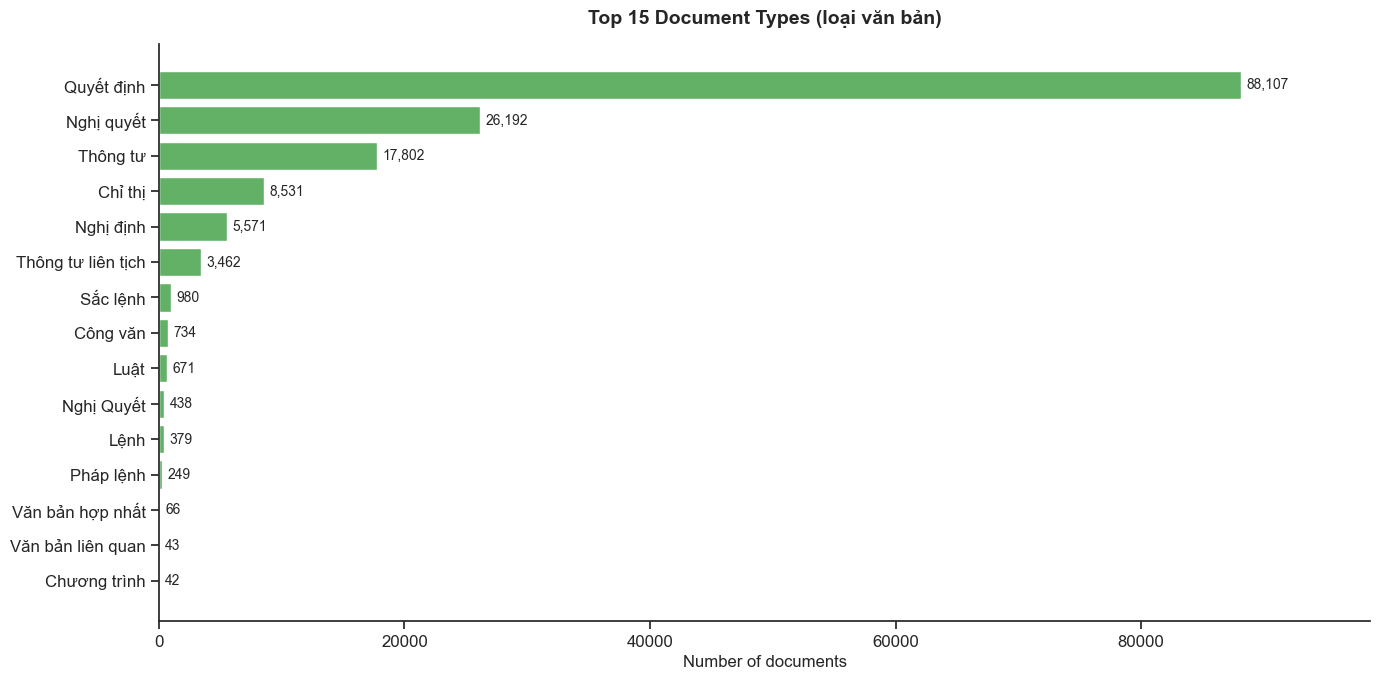

In [10]:
# === Cell 10: Distribution of loai_van_ban ===
display(Markdown("### 📊 Distribution of `loai_van_ban` (data/metadata)"))
df_meta = pl.scan_parquet(FILES["data/metadata"]).collect()

fig, ax = plt.subplots(figsize=(14, 7))
vc = df_meta["loai_van_ban"].drop_nulls().value_counts(sort=True).to_pandas()
vc.columns = ["loai_van_ban", "count"]
# Get Top 15 to match clean figure style
vc = vc.sort_values("count", ascending=False).head(15)
vc = vc.sort_values("count", ascending=True)

# Replace null/empty labels
vc["loai_van_ban"] = vc["loai_van_ban"].replace("", "(Unknown)").fillna("(Unknown)")
ax.barh(vc["loai_van_ban"], vc["count"], color="#63b167")
ax.set_xlabel("Number of documents", fontsize=12)
ax.set_title("Top 15 Document Types (loại văn bản)", fontsize=14, fontweight="bold", pad=15)

# Clean up axes
sns.despine()

# Add value labels
max_val = vc["count"].max()
for i, (_, row) in enumerate(vc.iterrows()):
    ax.text(row["count"] + max_val * 0.005, i, f'{row["count"]:,}', va="center", fontsize=10)
ax.set_xlim(right=max_val * 1.12)

plt.tight_layout()
plt.show()

### 📊 Distribution of `tinh_trang_hieu_luc` (data/metadata)

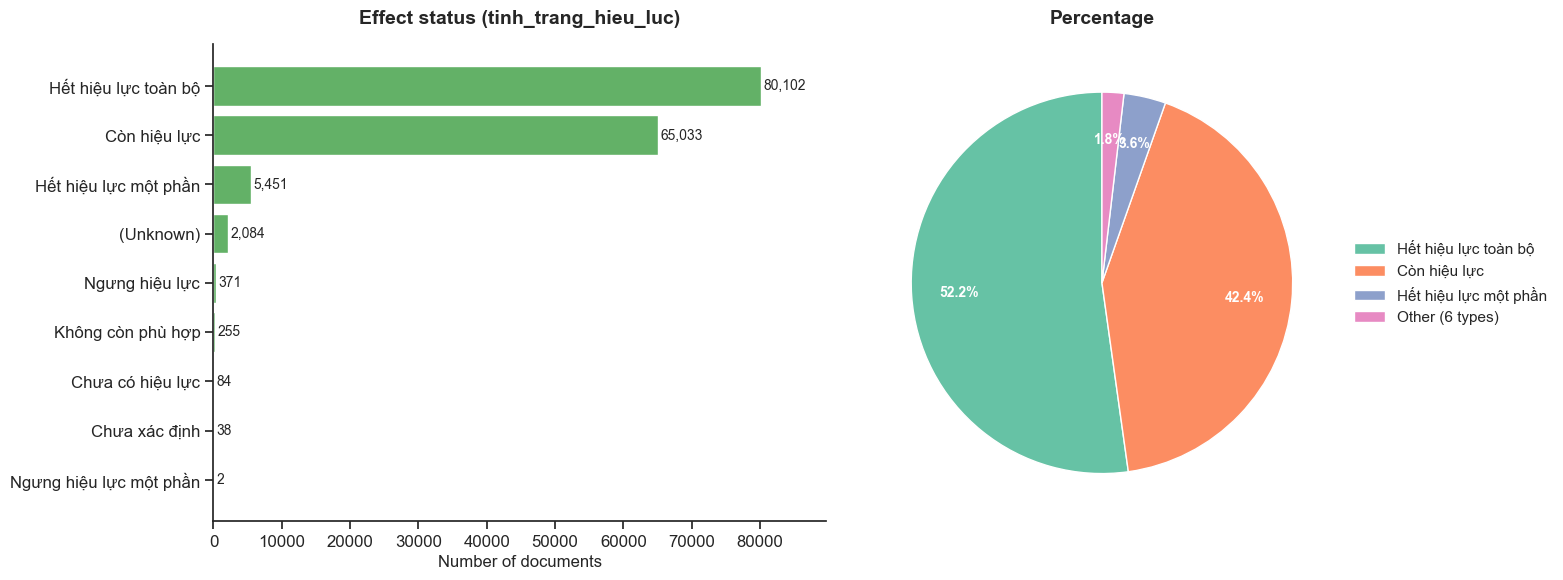

In [11]:
# === Cell 11: Distribution of tinh_trang_hieu_luc ===
display(Markdown("### 📊 Distribution of `tinh_trang_hieu_luc` (data/metadata)"))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

vc_status = df_meta["tinh_trang_hieu_luc"].drop_nulls().value_counts(sort=True).to_pandas()
vc_status.columns = ["tinh_trang_hieu_luc", "count"]
# Replace null/empty labels
vc_status["tinh_trang_hieu_luc"] = vc_status["tinh_trang_hieu_luc"].replace("", "(Unknown)").fillna("(Unknown)")

# Bar chart
vc_bar = vc_status.sort_values("count", ascending=True)
axes[0].barh(vc_bar["tinh_trang_hieu_luc"], vc_bar["count"], color="#63b167")
axes[0].set_title("Effect status (tinh_trang_hieu_luc)", fontsize=14, fontweight="bold", pad=15)
axes[0].set_xlabel("Number of documents", fontsize=12)
sns.despine(ax=axes[0])
max_val_0 = vc_bar["count"].max()
for i, (_, row) in enumerate(vc_bar.iterrows()):
    axes[0].text(row["count"] + max_val_0 * 0.005, i, f'{row["count"]:,}', va="center", fontsize=10)
axes[0].set_xlim(right=max_val_0 * 1.12)

# Pie chart – group small slices (<2%) into "Other"
total = vc_status["count"].sum()
vc_pie = vc_status.copy()
vc_pie["pct"] = vc_pie["count"] / total * 100
major = vc_pie[vc_pie["pct"] >= 2.0]
minor = vc_pie[vc_pie["pct"] < 2.0]
if len(minor) > 0:
    other_row = pd.DataFrame([{
        "tinh_trang_hieu_luc": f"Other ({len(minor)} types)",
        "count": minor["count"].sum(),
        "pct": minor["pct"].sum(),
    }])
    pie_data = pd.concat([major, other_row], ignore_index=True)
else:
    pie_data = major
pie_data = pie_data.sort_values("count", ascending=False)

wedges, texts, autotexts = axes[1].pie(
    pie_data["count"],
    labels=None,  # Remove direct labels to prevent overlap
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    colors=sns.color_palette("Set2", len(pie_data)),
)
for t in autotexts:
    t.set_fontsize(10)
    t.set_color("white")
    t.set_fontweight("bold")
    
axes[1].set_title("Percentage", fontsize=14, fontweight="bold", pad=15)
axes[1].legend(wedges, pie_data["tinh_trang_hieu_luc"], loc="center left", bbox_to_anchor=(1, 0.5), fontsize=11, frameon=False)

plt.tight_layout()
plt.show()

### 📊 Phân bố `relationship` (data/relationships)

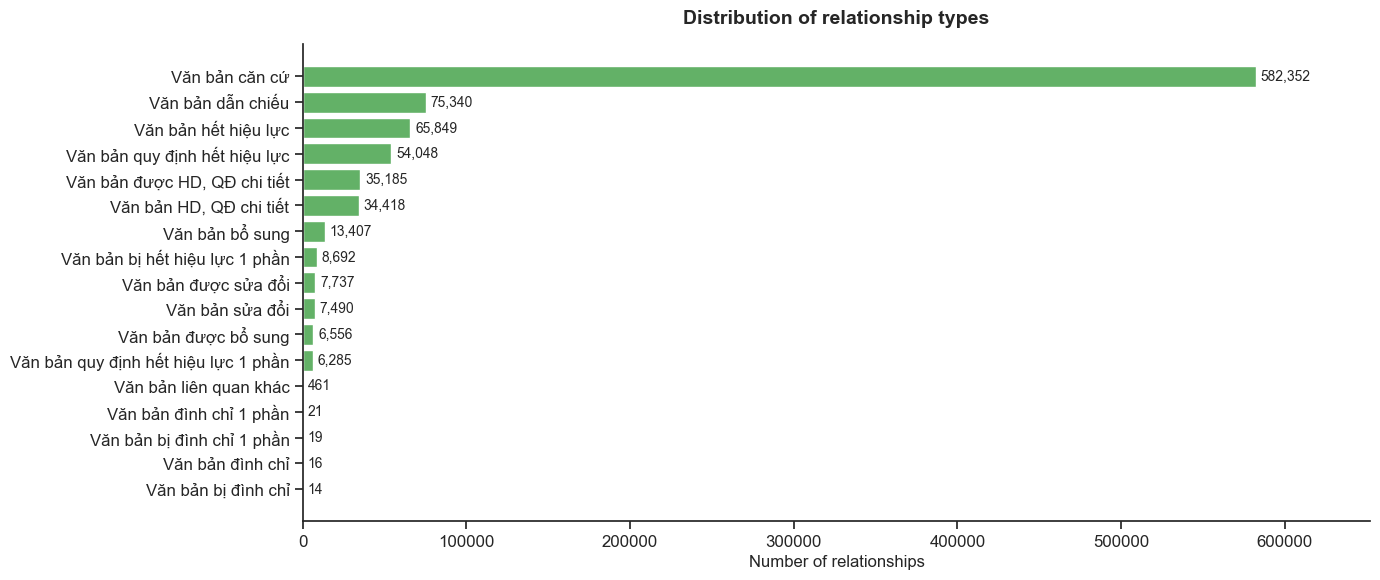

In [12]:
# === Cell 12: Biểu đồ relationship ===
display(Markdown("### 📊 Phân bố `relationship` (data/relationships)"))
df_rels = pl.scan_parquet(FILES["data/relationships"]).collect()

fig, ax = plt.subplots(figsize=(14, 6))
vc_rel = df_rels["relationship"].drop_nulls().value_counts(sort=True).to_pandas()
vc_rel.columns = ["relationship", "count"]
vc_rel = vc_rel.sort_values("count", ascending=True)
ax.barh(vc_rel["relationship"], vc_rel["count"], color="#63b167")
ax.set_xlabel("Number of relationships", fontsize=12)
ax.set_title("Distribution of relationship types", fontsize=14, fontweight="bold", pad=15)
sns.despine()
max_rel = vc_rel["count"].max()
for i, (_, row) in enumerate(vc_rel.iterrows()):
    ax.text(row["count"] + max_rel * 0.005, i, f'{row["count"]:,}', va="center", fontsize=10)
ax.set_xlim(right=max_rel * 1.12)
plt.tight_layout()
plt.show()

### 📊 Content length distribution (data/content)

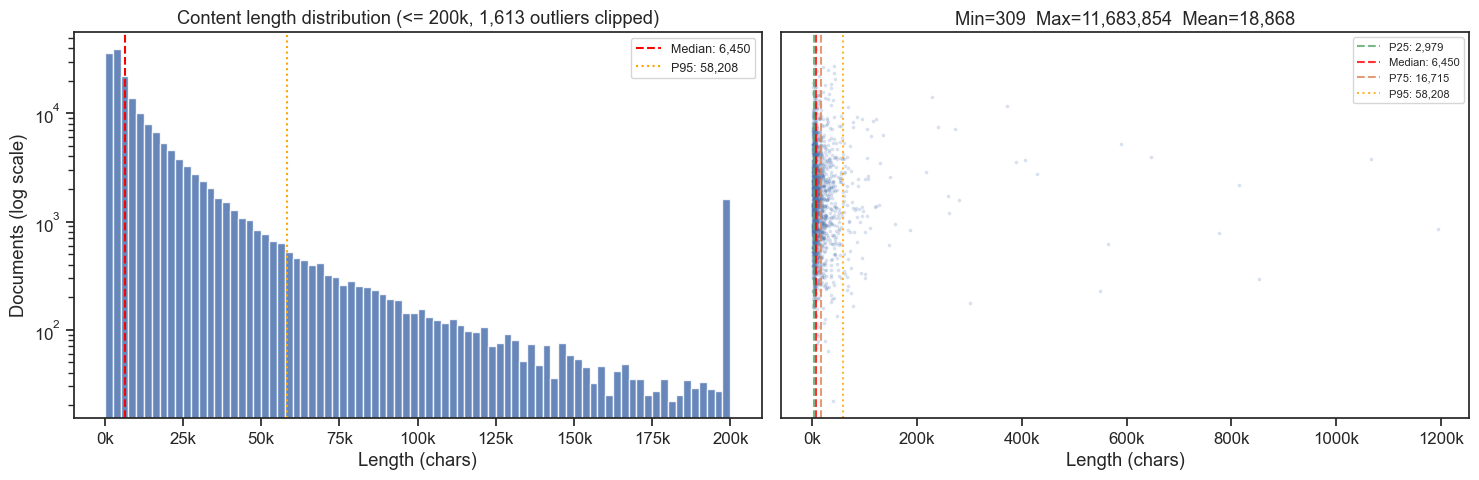

In [13]:
# === Cell 13: Content length distribution ===
display(Markdown("### 📊 Content length distribution (data/content)"))

# RAM-safe: Polars computes str length lazily, only the integer column is collected
content_lens_s = (
    pl.scan_parquet(FILES["data/content"])
    .select(pl.col("content_html").str.len_chars().alias("length"))
    .collect()
    .to_series()
)

CLIP_MAX = 200_000
n_outlier = int((content_lens_s > CLIP_MAX).sum())
med = float(content_lens_s.median())
p25 = float(content_lens_s.quantile(0.25))
p75 = float(content_lens_s.quantile(0.75))
p95 = float(content_lens_s.quantile(0.95))
len_min = int(content_lens_s.min())
len_max = int(content_lens_s.max())
len_mean = float(content_lens_s.mean())

# Convert to numpy for efficient histogram computation
lens_np = content_lens_s.clip(0, CLIP_MAX).to_numpy()
bins = np.linspace(0, CLIP_MAX, 81)
hist_counts, _ = np.histogram(lens_np, bins=bins)

# Sample for strip plot (small memory footprint)
strip_sample = content_lens_s.sample(min(2000, len(content_lens_s)), seed=42).to_numpy()
del content_lens_s, lens_np  # free memory

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Histogram via bar (pre-computed)
bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]
axes[0].bar(bin_centers, hist_counts, width=bin_width, color="#4C72B0", edgecolor="white", alpha=0.85)
axes[0].set_yscale("log")
axes[0].set_xlabel("Length (chars)")
axes[0].set_ylabel("Documents (log scale)")
axes[0].set_title(f"Content length distribution (<= {CLIP_MAX//1000}k, {n_outlier:,} outliers clipped)")
axes[0].axvline(med, color="red", linestyle="--", lw=1.5, label=f"Median: {med:,.0f}")
axes[0].axvline(p95, color="orange", linestyle=":", lw=1.5, label=f"P95: {p95:,.0f}")
axes[0].legend(fontsize=9)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

# Right: Strip plot + percentile lines (no violinplot to save RAM)
axes[1].scatter(strip_sample, np.random.normal(1, 0.04, len(strip_sample)),
                alpha=0.15, s=3, color="#4C72B0", zorder=2)
for val, label, color, ls in [(p25, "P25", "#55A868", "--"), (med, "Median", "red", "--"),
                               (p75, "P75", "#DD8452", "--"), (p95, "P95", "orange", ":")]:
    axes[1].axvline(val, color=color, linestyle=ls, lw=1.5, alpha=0.8,
                    label=f"{label}: {val:,.0f}")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].set_xlabel("Length (chars)")
axes[1].set_yticks([])
axes[1].set_title(f'Min={len_min:,}  Max={len_max:,}  Mean={len_mean:,.0f}')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

plt.tight_layout()
plt.show()

---
## 6. So sánh data/content vs legacy/content
Bộ nào đầy đủ hơn? Nội dung có khác nhau không?

In [14]:
# === Cell 14: So sánh content datasets ===
display(Markdown("### 🔍 So sánh data/content vs legacy/content"))

cmp = compare_content_datasets(FILES["data/content"], FILES["legacy/content"])

# Bảng tổng hợp
summary_rows = [
    {"Metric": "Tổng số dòng", "data/content": f'{cmp["n_data"]:,}', "legacy/content": f'{cmp["n_legacy"]:,}'},
    {"Metric": "Cột nội dung", "data/content": cmp["content_col_data"], "legacy/content": cmp["content_col_legacy"]},
    {"Metric": "Format nội dung", "data/content": "HTML", "legacy/content": "Text thuần"},
    {"Metric": "ID overlap", "data/content": f'{cmp["n_overlap"]:,}', "legacy/content": f'{cmp["n_overlap"]:,}'},
    {"Metric": "ID chỉ có ở bộ này", "data/content": f'{cmp["n_only_data"]:,}', "legacy/content": f'{cmp["n_only_legacy"]:,}'},
]
display(pl.DataFrame(summary_rows))

### 🔍 So sánh data/content vs legacy/content

Metric,data/content,legacy/content
str,str,str
"""Tổng số dòng""","""178,665""","""518,235"""
"""Cột nội dung""","""content_html""","""content"""
"""Format nội dung""","""HTML""","""Text thuần"""
"""ID overlap""","""112,388""","""112,388"""
"""ID chỉ có ở bộ này""","""36,663""","""405,847"""


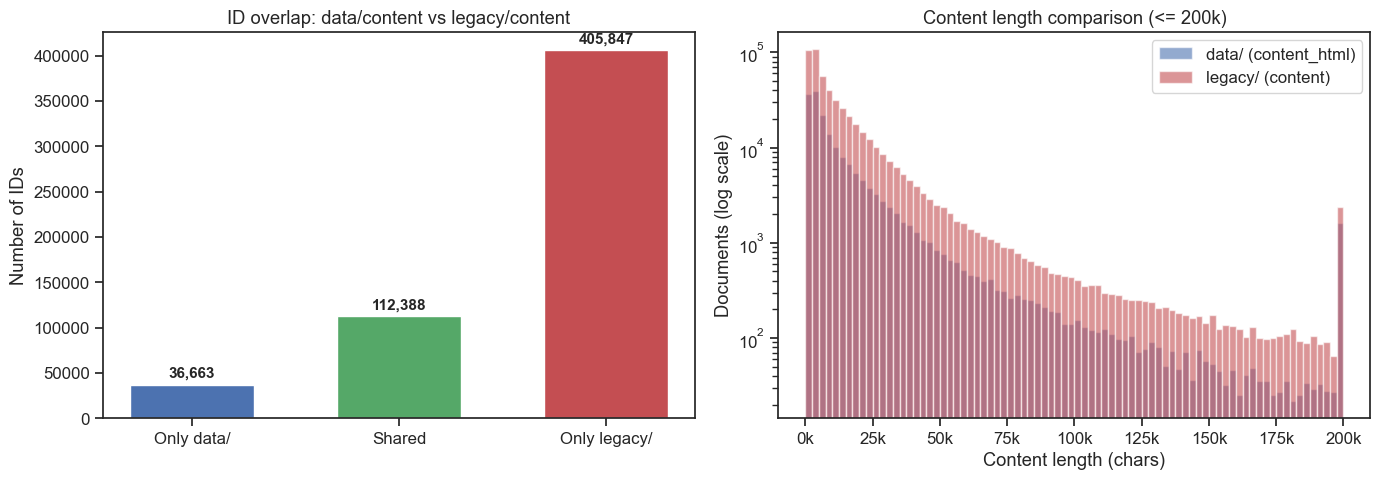


**Nhận xét:**
- `legacy/content` có **518,235** dòng, `data/content` có 178,665 dòng
- `data/content` chứa **HTML** (`content_html`), `legacy/content` chứa **text thuần** (`content`)
- Độ dài trung vị: data/ = **6,450** ký tự, legacy/ = **6,910** ký tự
- **112,388** ID chung, **405,847** ID chỉ có trong legacy/


In [15]:
# === Cell 15: Biểu đồ so sánh ID và độ dài content ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Venn-like bar chart
labels = ["Only data/", "Shared", "Only legacy/"]
values = [cmp["n_only_data"], cmp["n_overlap"], cmp["n_only_legacy"]]
colors = ["#4C72B0", "#55A868", "#C44E52"]
axes[0].bar(labels, values, color=colors, edgecolor="white", width=0.6)
axes[0].set_title("ID overlap: data/content vs legacy/content")
axes[0].set_ylabel("Number of IDs")
for i, v in enumerate(values):
    axes[0].text(i, v + max(values)*0.02, f"{v:,}", ha="center", fontsize=11, fontweight="bold")
# Content length comparison – use pre-computed histogram (RAM-safe)
bin_centers = (cmp["hist_bins"][:-1] + cmp["hist_bins"][1:]) / 2
bin_width = cmp["hist_bins"][1] - cmp["hist_bins"][0]
axes[1].bar(bin_centers, cmp["hist_data"], width=bin_width, alpha=0.6,
            label=f'data/ ({cmp["content_col_data"]})', color="#4C72B0")
axes[1].bar(bin_centers, cmp["hist_legacy"], width=bin_width, alpha=0.6,
            label=f'legacy/ ({cmp["content_col_legacy"]})', color="#C44E52")
axes[1].set_yscale("log")
axes[1].set_xlabel("Content length (chars)")
axes[1].set_ylabel("Documents (log scale)")
axes[1].set_title("Content length comparison (<= 200k)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
axes[1].legend()

plt.tight_layout()
plt.show()

# Nhận xét
data_median = cmp["median_data"]
legacy_median = cmp["median_legacy"]
display(Markdown(f"""
**Nhận xét:**
- `legacy/content` có **{cmp['n_legacy']:,}** dòng, `data/content` có {cmp['n_data']:,} dòng
- `data/content` chứa **HTML** (`content_html`), `legacy/content` chứa **text thuần** (`content`)
- Độ dài trung vị: data/ = **{data_median:,.0f}** ký tự, legacy/ = **{legacy_median:,.0f}** ký tự
- **{cmp['n_overlap']:,}** ID chung, **{cmp['n_only_legacy']:,}** ID chỉ có trong legacy/
"""))

---
## 6.5 So sánh data/metadata vs legacy/metadata
Cột nào tương ứng? Dữ liệu khác gì?

In [16]:
# === Cell 15b: So sánh metadata datasets ===
display(Markdown("### 🔍 So sánh data/metadata vs legacy/metadata"))

mcmp = compare_metadata_datasets(FILES["data/metadata"], FILES["legacy/metadata"])

# Bảng column mapping
map_rows = [{"data/ (Việt)": k, "legacy/ (Eng)": v} for k, v in mcmp["col_map"].items()]
display(Markdown("**🗓️ Column mapping:**"))
display(pl.DataFrame(map_rows))

meta_summary = [
    {"Metric": "Tổng số dòng", "data/metadata": f'{mcmp["n_data"]:,}', "legacy/metadata": f'{mcmp["n_legacy"]:,}'},
    {"Metric": "Số cột", "data/metadata": str(len(mcmp["schema_data"])), "legacy/metadata": str(len(mcmp["schema_legacy"]))},
    {"Metric": "Cột chỉ có ở data/", "data/metadata": ", ".join(mcmp["data_only_cols"]) or "—", "legacy/metadata": "—"},
    {"Metric": "Cột chỉ có ở legacy/", "data/metadata": "—", "legacy/metadata": ", ".join(mcmp["legacy_only_cols"]) or "—"},
    {"Metric": "ID overlap", "data/metadata": f'{mcmp["n_overlap"]:,}', "legacy/metadata": f'{mcmp["n_overlap"]:,}'},
    {"Metric": "ID chỉ có ở bộ này", "data/metadata": f'{mcmp["n_only_data"]:,}', "legacy/metadata": f'{mcmp["n_only_legacy"]:,}'},
]
display(pl.DataFrame(meta_summary))

### 🔍 So sánh data/metadata vs legacy/metadata

**🗓️ Column mapping:**

data/ (Việt),legacy/ (Eng)
str,str
"""so_ky_hieu""","""document_number"""
"""title""","""title"""
"""loai_van_ban""","""legal_type"""
"""co_quan_ban_hanh""","""issuing_authority"""
"""ngay_ban_hanh""","""issuance_date"""
"""ngay_co_hieu_luc""","""effect_date"""
"""ngay_het_hieu_luc""","""effectless_date"""
"""tinh_trang_hieu_luc""","""effect_status"""
"""nguoi_ky""","""signers"""


Metric,data/metadata,legacy/metadata
str,str,str
"""Tổng số dòng""","""153,420""","""518,601"""
"""Số cột""","""17""","""11"""
"""Cột chỉ có ở data/""","""nguon_thu_thap, ngay_dang_cong_bao, nganh, linh_vuc, chuc_danh, pham_vi, thong_tin_ap_dung""","""—"""
"""Cột chỉ có ở legacy/""","""—""","""legal_sectors"""
"""ID overlap""","""116,223""","""116,223"""
"""ID chỉ có ở bộ này""","""37,197""","""402,378"""


### 🏷️ loai_van_ban vs legal_type

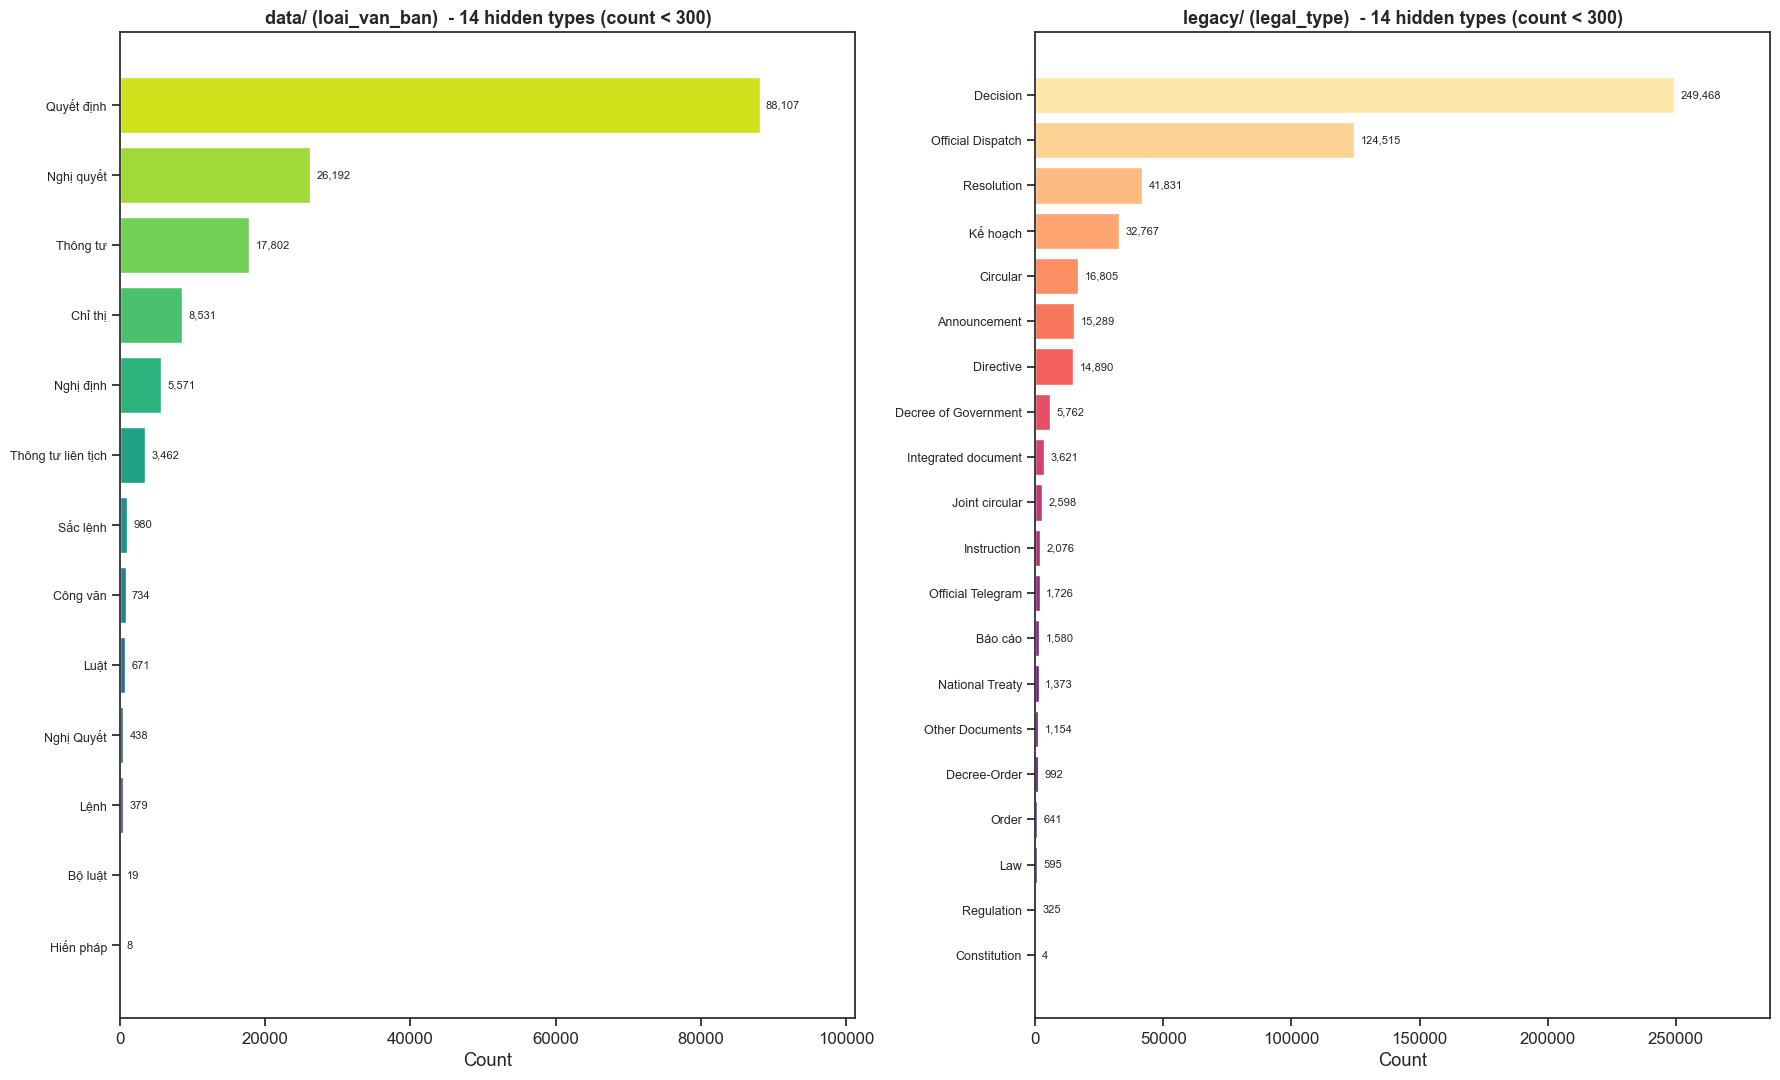

### 🏷️ tinh_trang_hieu_luc vs effect_status

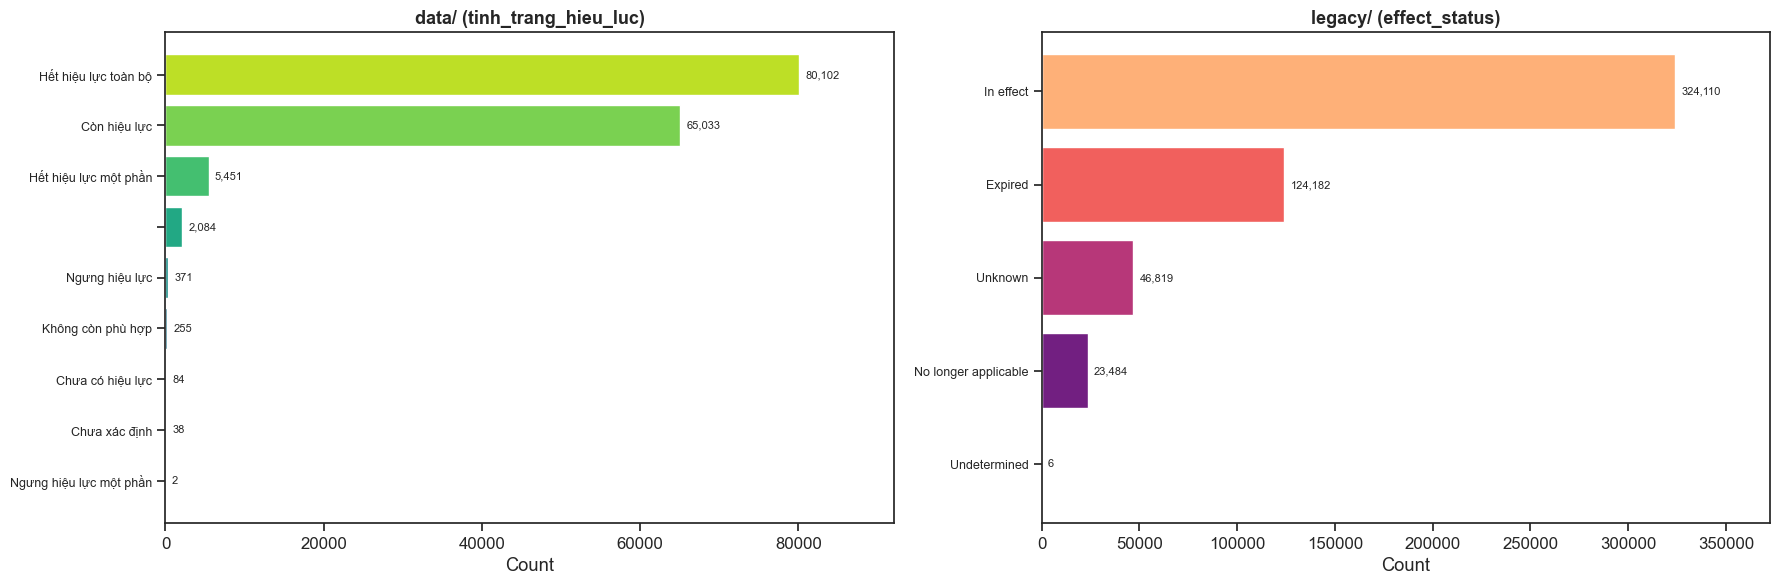


**Nhận xét metadata:**
- `legacy/metadata` có **518,601** dòng vs `data/metadata` **153,420** dòng
- `data/` dùng tên cột **tiếng Việt**, `legacy/` dùng tên **tiếng Anh**
- Cột chỉ có trong data/: **nguon_thu_thap, ngay_dang_cong_bao, nganh, linh_vuc, chuc_danh, pham_vi, thong_tin_ap_dung**
- Cột chỉ có trong legacy/: **legal_sectors**
- **116,223** ID chung, **37,197** chỉ data/, **402,378** chỉ legacy/


In [17]:
# === Cell 15c: So sánh categorical columns giữa 2 bộ ===

# Categories to always keep even if count < threshold (notable legal types)
_KEEP_ALWAYS = {"Bộ luật", "Hiến pháp", "Constitution", "Code"}
_MIN_COUNT = 300  # hide categories below this threshold

for pair_name, pair_data in mcmp["cat_comparisons"].items():
    display(Markdown(f"### 🏷️ {pair_name}"))

    # For loai_van_ban vs legal_type: filter small categories
    is_type_chart = "loai_van_ban" in pair_name

    filtered_pair = {}
    for side_key, vc_df in [("data", pair_data["data"]), ("legacy", pair_data["legacy"])]:
        pdf = vc_df.to_pandas()
        if is_type_chart:
            n_before = len(pdf)
            mask = (pdf["count"] >= _MIN_COUNT) | (pdf["value"].isin(_KEEP_ALWAYS))
            pdf = pdf[mask]
            n_hidden = n_before - len(pdf)
        else:
            n_hidden = 0
        filtered_pair[side_key] = (pdf, n_hidden)

    # Dynamic height: scale based on max number of categories across both sides
    n_max = max(len(filtered_pair["data"][0]), len(filtered_pair["legacy"][0]))
    fig_h = max(6, n_max * 0.45 + 2)  # at least 6, ~0.45 inch per category
    fig, axes = plt.subplots(1, 2, figsize=(18, fig_h))

    for i, (label, side_key) in enumerate([("data/", "data"), ("legacy/", "legacy")]):
        pdf, n_hidden = filtered_pair[side_key]
        pdf = pdf.sort_values("count", ascending=True)
        axes[i].barh(pdf["value"], pdf["count"],
                      color=sns.color_palette("viridis" if i == 0 else "magma", len(pdf)))
        subtitle = f"{label} ({pair_name.split(' vs ')[i]})"
        if n_hidden > 0:
            subtitle += f"  - {n_hidden} hidden types (count < {_MIN_COUNT})"
        axes[i].set_title(subtitle, fontsize=13, fontweight="bold")
        axes[i].set_xlabel("Count")
        axes[i].tick_params(axis="y", labelsize=9)
        max_cnt = max(pdf["count"])
        for j, (_, row) in enumerate(pdf.iterrows()):
            axes[i].text(row["count"] + max_cnt * 0.01, j,
                         f'{row["count"]:,}', va="center", fontsize=8)
        axes[i].set_xlim(right=max_cnt * 1.15)

    plt.tight_layout()
    plt.show()

display(Markdown(f"""
**Nhận xét metadata:**
- `legacy/metadata` có **{mcmp['n_legacy']:,}** dòng vs `data/metadata` **{mcmp['n_data']:,}** dòng
- `data/` dùng tên cột **tiếng Việt**, `legacy/` dùng tên **tiếng Anh**
- Cột chỉ có trong data/: **{', '.join(mcmp['data_only_cols']) or 'Không'}**
- Cột chỉ có trong legacy/: **{', '.join(mcmp['legacy_only_cols']) or 'Không'}**
- **{mcmp['n_overlap']:,}** ID chung, **{mcmp['n_only_data']:,}** chỉ data/, **{mcmp['n_only_legacy']:,}** chỉ legacy/
"""))

---
## 7. Mối quan hệ giữa 3 bảng: content, metadata, relationships
Phân tích cách các bảng liên kết với nhau qua cột `id`.

### 🔗 Sơ đồ quan hệ (ER Diagram)

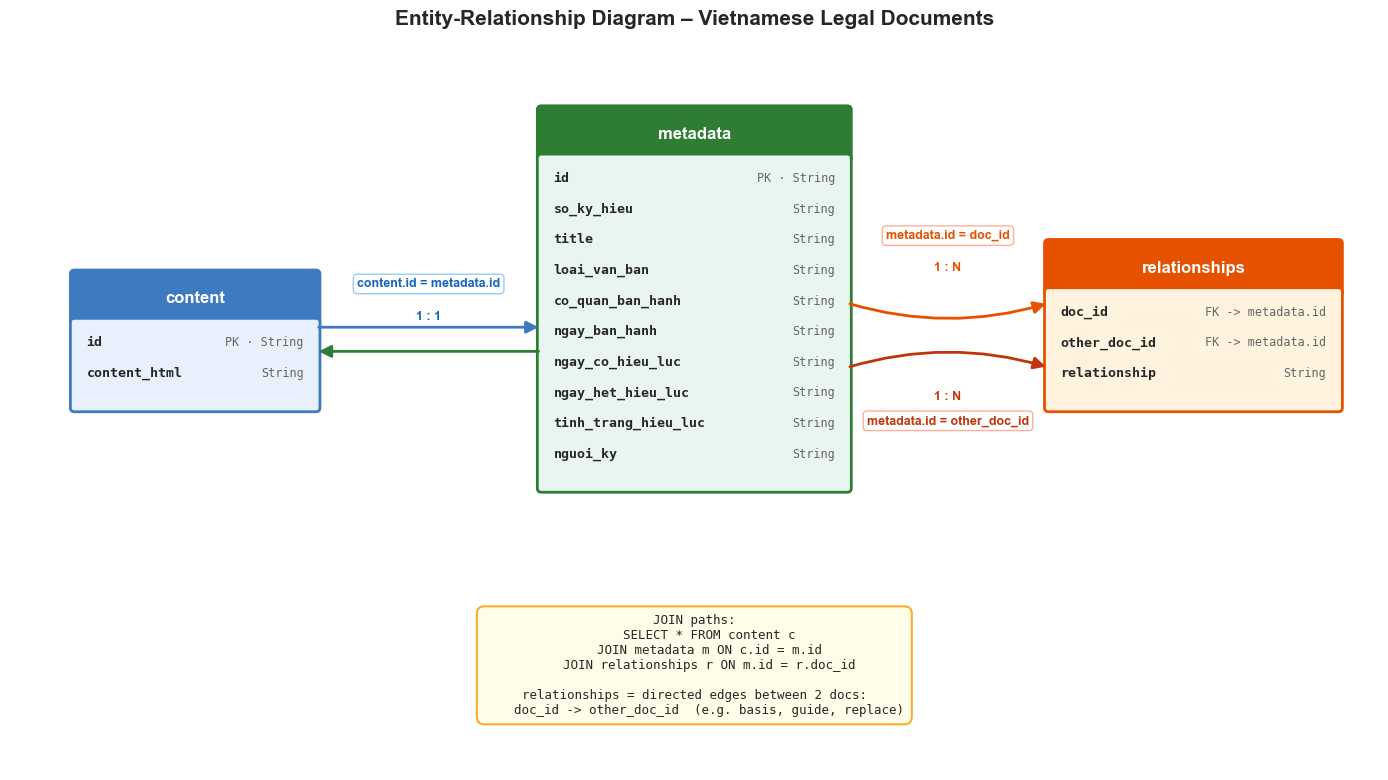

In [18]:
# === Cell 16: ER Diagram – Sơ đồ quan hệ 3 bảng ===
display(Markdown("### 🔗 Sơ đồ quan hệ (ER Diagram)"))

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 8))
ax.set_xlim(-0.5, 16.5)
ax.set_ylim(-0.5, 8.5)
ax.axis("off")
ax.set_aspect("equal")

def draw_entity(ax, x, y, title, cols, w=3.2, color="#4C72B0", bg="#E8F0FE"):
    """Vẽ entity box với header + body."""
    line_h = 0.38
    h_header = 0.6
    h_body = len(cols) * line_h + 0.3
    h_total = h_header + h_body

    # Header
    header = FancyBboxPatch((x - w/2, y + h_body), w, h_header,
                            boxstyle="round,pad=0.05", facecolor=color,
                            edgecolor=color, linewidth=2, zorder=3)
    ax.add_patch(header)
    ax.text(x, y + h_body + h_header/2, title, ha="center", va="center",
            fontsize=12, fontweight="bold", color="white", zorder=4)

    # Body
    body = FancyBboxPatch((x - w/2, y), w, h_body,
                          boxstyle="round,pad=0.05", facecolor=bg,
                          edgecolor=color, linewidth=2, zorder=3)
    ax.add_patch(body)

    for i, (col_name, col_info) in enumerate(cols):
        yy = y + h_body - 0.25 - i * line_h
        if col_info:
            ax.text(x - w/2 + 0.15, yy, col_name, fontsize=9.5, va="center",
                    fontfamily="monospace", fontweight="bold", zorder=4)
            ax.text(x + w/2 - 0.15, yy, col_info, fontsize=8.5, va="center",
                    ha="right", color="#666", fontfamily="monospace", zorder=4)
        else:
            ax.text(x - w/2 + 0.15, yy, col_name, fontsize=9.5, va="center",
                    fontfamily="monospace", zorder=4)

    return x, y, w, h_total, h_body

# ── Draw entities ──
cx, cy = 1.8, 4.0
draw_entity(ax, cx, cy, "content", [
    ("id", "PK · String"),
    ("content_html", "String"),
], w=3.0, color="#3D7ABF", bg="#E8F0FE")

mx, my = 8.0, 3.0
draw_entity(ax, mx, my, "metadata", [
    ("id", "PK · String"),
    ("so_ky_hieu", "String"),
    ("title", "String"),
    ("loai_van_ban", "String"),
    ("co_quan_ban_hanh", "String"),
    ("ngay_ban_hanh", "String"),
    ("ngay_co_hieu_luc", "String"),
    ("ngay_het_hieu_luc", "String"),
    ("tinh_trang_hieu_luc", "String"),
    ("nguoi_ky", "String"),
], w=3.8, color="#2E7D32", bg="#E8F6EF")

rx, ry = 14.2, 4.0
draw_entity(ax, rx, ry, "relationships", [
    ("doc_id", "FK -> metadata.id"),
    ("other_doc_id", "FK -> metadata.id"),
    ("relationship", "String"),
], w=3.6, color="#E65100", bg="#FFF3E0")

# ── Arrows ──
arrow_kw = dict(arrowstyle="-|>", lw=2, mutation_scale=18, zorder=5)

# content ↔ metadata
ax.annotate("", xy=(6.1, 5.0), xytext=(3.3, 5.0),
            arrowprops=dict(**arrow_kw, color="#3D7ABF"))
ax.annotate("", xy=(3.3, 4.7), xytext=(6.1, 4.7),
            arrowprops=dict(**arrow_kw, color="#2E7D32"))
ax.text(4.7, 5.5, "content.id = metadata.id", fontsize=9, ha="center",
        fontweight="bold", color="#1565C0",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#90CAF9", alpha=0.95))
ax.text(4.7, 5.1, "1 : 1", fontsize=9, ha="center", color="#1565C0", fontweight="bold")

# metadata ↔ relationships
ax.annotate("", xy=(12.4, 5.3), xytext=(9.9, 5.3),
            arrowprops=dict(**arrow_kw, color="#E65100",
                            connectionstyle="arc3,rad=0.15"))
ax.text(11.15, 6.1, "metadata.id = doc_id", fontsize=9, ha="center",
        fontweight="bold", color="#E65100",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#FFAB91", alpha=0.95))
ax.text(11.15, 5.7, "1 : N", fontsize=9, ha="center", color="#E65100", fontweight="bold")

ax.annotate("", xy=(12.4, 4.5), xytext=(9.9, 4.5),
            arrowprops=dict(**arrow_kw, color="#BF360C",
                            connectionstyle="arc3,rad=-0.15"))
ax.text(11.15, 3.8, "metadata.id = other_doc_id", fontsize=9, ha="center",
        fontweight="bold", color="#BF360C",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#FFAB91", alpha=0.95))
ax.text(11.15, 4.1, "1 : N", fontsize=9, ha="center", color="#BF360C", fontweight="bold")

# -- Legend --
legend_text = (
    "JOIN paths:\n"
    "    SELECT * FROM content c\n"
    "    JOIN metadata m ON c.id = m.id\n"
    "    JOIN relationships r ON m.id = r.doc_id\n\n"
    "relationships = directed edges between 2 docs:\n"
    "    doc_id -> other_doc_id  (e.g. basis, guide, replace)"
)
ax.text(8.0, 0.8, legend_text, fontsize=9, ha="center", va="center",
        fontfamily="monospace",
        bbox=dict(boxstyle="round,pad=0.6", facecolor="#FFFDE7",
                  edgecolor="#F9A825", linewidth=1.5, alpha=0.95))

ax.set_title("Entity-Relationship Diagram – Vietnamese Legal Documents",
             fontsize=15, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

In [19]:
# === Cell 17: Thống kê ID coverage giữa 3 bảng ===
display(Markdown("### 📊 ID Coverage giữa 3 bảng (data/)"))

cov = get_id_coverage(
    FILES["data/content"],
    FILES["data/metadata"],
    FILES["data/relationships"],
)

cov_rows = [
    {"Section": "Row counts", "Metric": "content - unique IDs", "Value": f'{cov["n_content"]:,}'},
    {"Section": "Row counts", "Metric": "metadata - unique IDs", "Value": f'{cov["n_metadata"]:,}'},
    {"Section": "Row counts", "Metric": "relationships - total rows", "Value": f'{cov["n_rel_rows"]:,}'},
    {"Section": "Row counts", "Metric": "relationships - unique docs involved", "Value": f'{cov["n_rel_unique_docs"]:,}'},
    {"Section": "ID overlap", "Metric": "content \u2229 metadata", "Value": f'{cov["content_in_metadata"]:,}'},
    {"Section": "ID overlap", "Metric": "content \\ metadata (only in content)", "Value": f'{cov["content_not_in_metadata"]:,}'},
    {"Section": "ID overlap", "Metric": "metadata \\ content (only in metadata)", "Value": f'{cov["metadata_not_in_content"]:,}'},
    {"Section": "FK coverage", "Metric": "rel.doc_id in metadata", "Value": f'{cov["rel_src_in_metadata"]:,}'},
    {"Section": "FK coverage", "Metric": "rel.doc_id NOT in metadata", "Value": f'{cov["rel_src_not_in_metadata"]:,}'},
    {"Section": "FK coverage", "Metric": "rel.other_doc_id in metadata", "Value": f'{cov["rel_tgt_in_metadata"]:,}'},
    {"Section": "FK coverage", "Metric": "rel.other_doc_id NOT in metadata", "Value": f'{cov["rel_tgt_not_in_metadata"]:,}'},
]
display(pl.DataFrame(cov_rows))

### 📊 ID Coverage giữa 3 bảng (data/)

Section,Metric,Value
str,str,str
"""Row counts""","""content - unique IDs""","""149,051"""
"""Row counts""","""metadata - unique IDs""","""153,420"""
"""Row counts""","""relationships - total rows""","""897,890"""
"""Row counts""","""relationships - unique docs involved""","""153,687"""
"""ID overlap""","""content ∩ metadata""","""146,857"""
"""ID overlap""","""content \ metadata (only in content)""","""2,194"""
"""ID overlap""","""metadata \ content (only in metadata)""","""6,563"""
"""FK coverage""","""rel.doc_id in metadata""","""131,918"""
"""FK coverage""","""rel.doc_id NOT in metadata""","""0"""


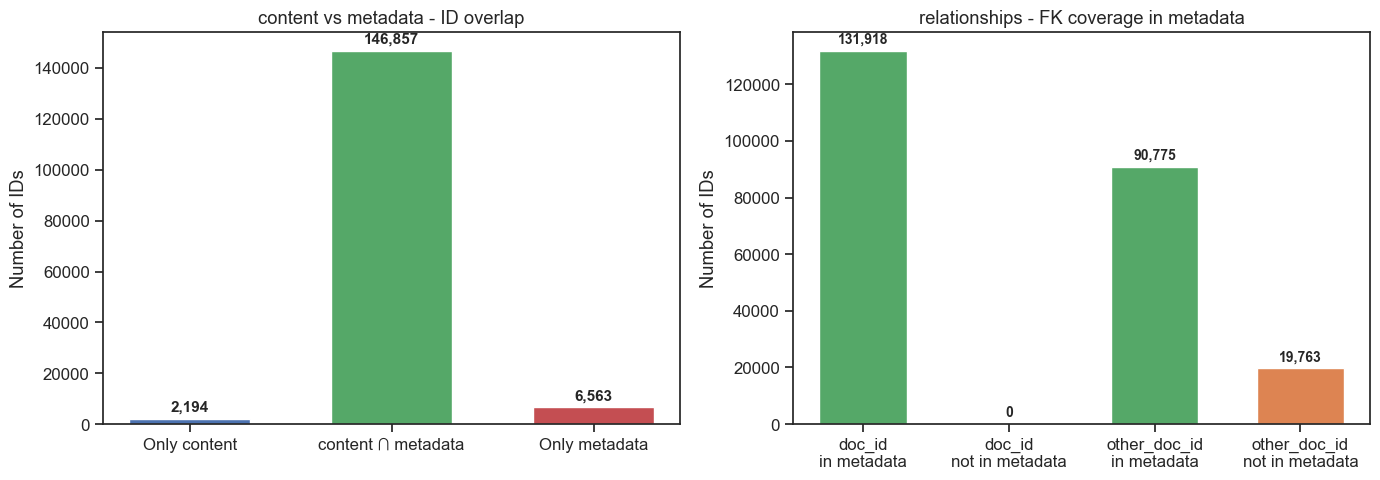

In [20]:
# === Cell 18: Biểu đồ Venn-like – ID coverage ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Content vs Metadata
labels1 = ["Only content", "content \u2229 metadata", "Only metadata"]
vals1 = [cov["content_not_in_metadata"], cov["content_in_metadata"], cov["metadata_not_in_content"]]
colors1 = ["#4C72B0", "#55A868", "#C44E52"]
bars1 = axes[0].bar(labels1, vals1, color=colors1, edgecolor="white", width=0.6)
axes[0].set_title("content vs metadata - ID overlap")
axes[0].set_ylabel("Number of IDs")
for bar, v in zip(bars1, vals1):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + max(vals1)*0.02,
                 f"{v:,}", ha="center", fontsize=11, fontweight="bold")

# Relationships coverage
labels2 = ["doc_id\nin metadata", "doc_id\nnot in metadata",
           "other_doc_id\nin metadata", "other_doc_id\nnot in metadata"]
vals2 = [cov["rel_src_in_metadata"], cov["rel_src_not_in_metadata"],
         cov["rel_tgt_in_metadata"], cov["rel_tgt_not_in_metadata"]]
colors2 = ["#55A868", "#DD8452", "#55A868", "#DD8452"]
bars2 = axes[1].bar(labels2, vals2, color=colors2, edgecolor="white", width=0.6)
axes[1].set_title("relationships - FK coverage in metadata")
axes[1].set_ylabel("Number of IDs")
for bar, v in zip(bars2, vals2):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + max(vals2)*0.02,
                 f"{v:,}", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

---
## 8. Data Quality – Null heatmap

### 🧹 Data Quality – Tỷ lệ NULL theo cột

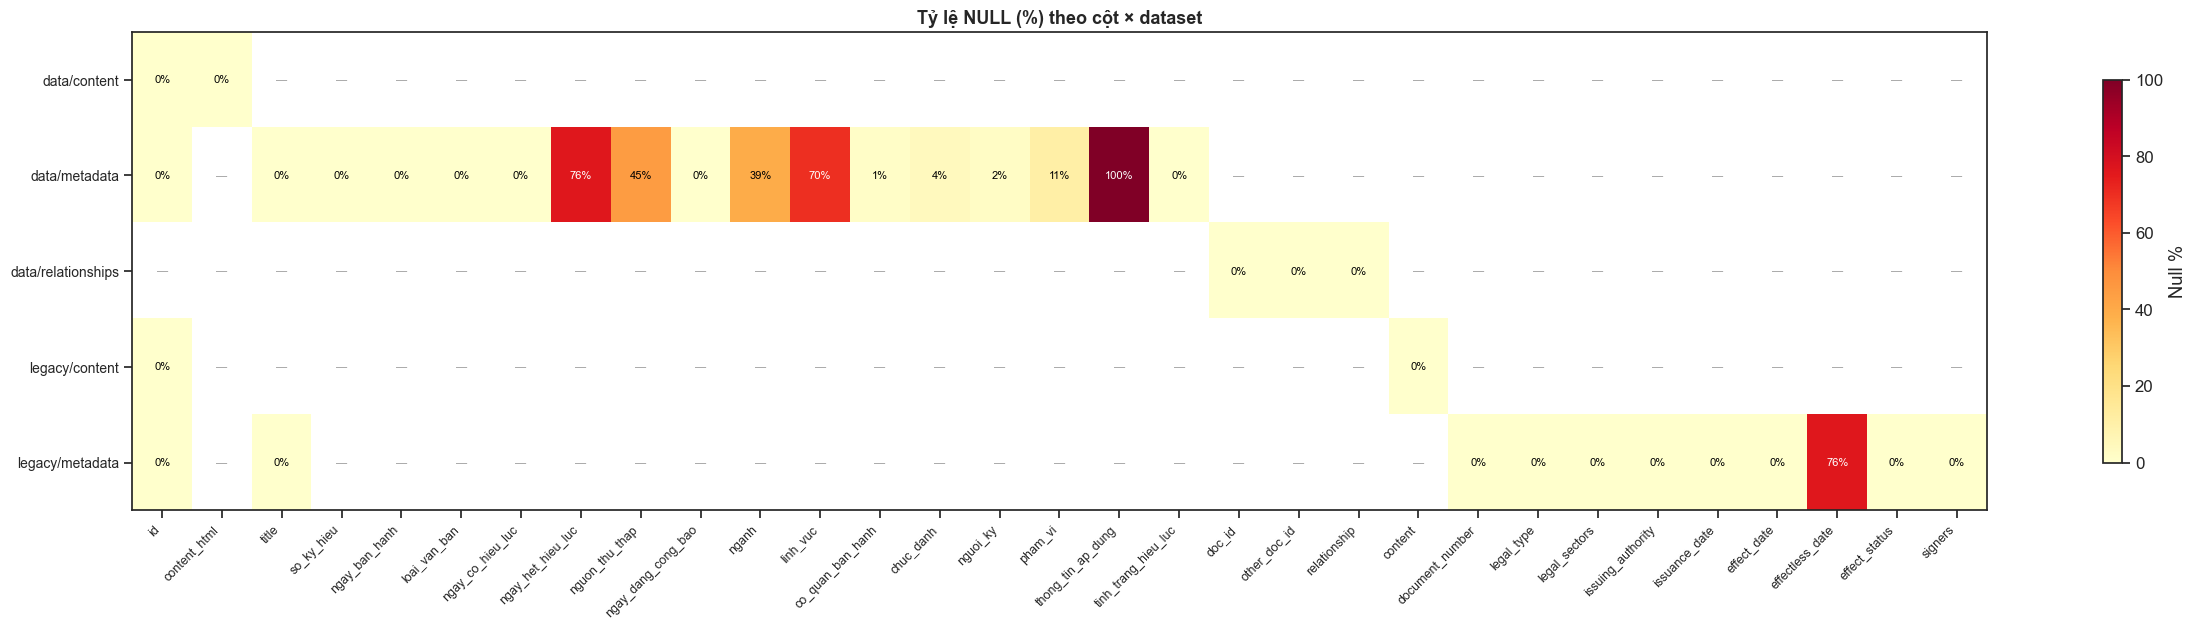

In [21]:
# === Cell 19: Data Quality Heatmap ===
display(Markdown("### 🧹 Data Quality – Tỷ lệ NULL theo cột"))

quality_data = {}
for name, path in FILES.items():
    if not os.path.exists(path):
        continue
    # RAM-safe: compute null counts lazily without loading full data
    schema = pl.scan_parquet(path).collect_schema()
    total_q = pl.scan_parquet(path).select(pl.len()).collect().item()
    null_pcts = {}
    # Compute all null counts in a single lazy query
    null_exprs = [pl.col(col).null_count().alias(col) for col in schema.names()]
    null_counts = pl.scan_parquet(path).select(null_exprs).collect()
    for col in schema.names():
        null_pcts[col] = round(null_counts[col][0] / total_q * 100, 1)
    quality_data[name] = null_pcts

# Build matrix – all columns across datasets
all_cols = []
for v in quality_data.values():
    for c in v:
        if c not in all_cols:
            all_cols.append(c)

matrix = []
ds_labels = []
for ds_name, cols_dict in quality_data.items():
    row = [cols_dict.get(c, float("nan")) for c in all_cols]
    matrix.append(row)
    ds_labels.append(ds_name)

fig, ax = plt.subplots(figsize=(max(14, len(all_cols) * 0.8), len(ds_labels) * 0.9 + 2))
mat = np.array(matrix)
im = ax.imshow(mat, cmap="YlOrRd", aspect="auto", vmin=0, vmax=100)

ax.set_xticks(range(len(all_cols)))
ax.set_xticklabels(all_cols, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(ds_labels)))
ax.set_yticklabels(ds_labels, fontsize=10)

# Annotate cells
for i in range(len(ds_labels)):
    for j in range(len(all_cols)):
        val = mat[i, j]
        if np.isnan(val):
            ax.text(j, i, "—", ha="center", va="center", fontsize=8, color="#999")
        else:
            color = "white" if val > 50 else "black"
            ax.text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=8, color=color)

plt.colorbar(im, ax=ax, label="Null %", shrink=0.8)
ax.set_title("Tỷ lệ NULL (%) theo cột × dataset", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 9. Phân tích thời gian – Ngày ban hành

### 📅 Phân bố thời gian ban hành văn bản

Parse thành công: **153,335** / 153,420 (99.9%)

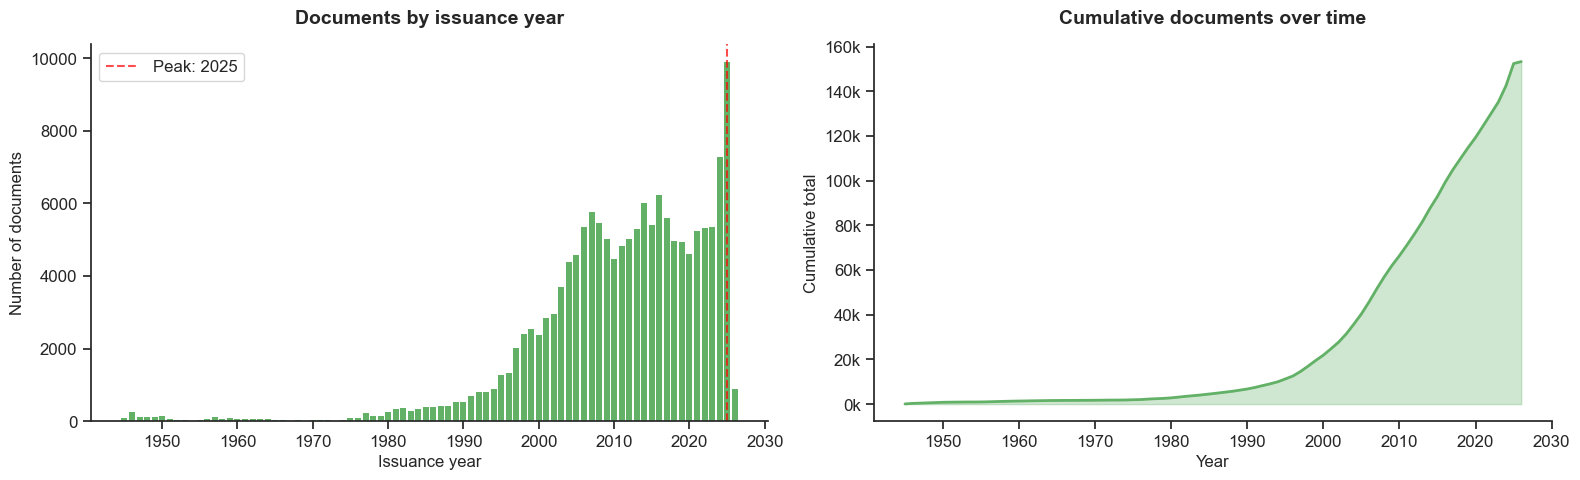

In [22]:
# === Cell 20: Temporal analysis – ngay_ban_hanh ===
display(Markdown("### 📅 Phân bố thời gian ban hành văn bản"))

df_time = (
    pl.scan_parquet(FILES["data/metadata"])
    .select("ngay_ban_hanh")
    .collect()
)

# Parse dates – format varies, try common patterns
parsed = df_time.with_columns(
    pl.col("ngay_ban_hanh")
    .str.to_date("%d/%m/%Y", strict=False)
    .alias("date")
).filter(pl.col("date").is_not_null())

n_parsed = len(parsed)
n_total = len(df_time)
display(Markdown(f"Parse thành công: **{n_parsed:,}** / {n_total:,} ({n_parsed/n_total*100:.1f}%)"))

# Extract year
yearly = (
    parsed
    .with_columns(pl.col("date").dt.year().alias("year"))
    .group_by("year")
    .agg(pl.len().alias("count"))
    .sort("year")
    .filter((pl.col("year") >= 1945) & (pl.col("year") <= 2040))
    .to_pandas()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Timeline bar chart
axes[0].bar(yearly["year"], yearly["count"], color="#63b167", edgecolor="none", width=0.8)
axes[0].set_xlabel("Issuance year", fontsize=12)
axes[0].set_ylabel("Number of documents", fontsize=12)
axes[0].set_title("Documents by issuance year", fontsize=14, fontweight="bold", pad=15)
axes[0].axvline(yearly.loc[yearly["count"].idxmax(), "year"], color="red", linestyle="--",
                alpha=0.7, label=f'Peak: {yearly.loc[yearly["count"].idxmax(), "year"]:.0f}')
axes[0].legend()
sns.despine(ax=axes[0])

# Cumulative
yearly_sorted = yearly.sort_values("year")
yearly_sorted["cumsum"] = yearly_sorted["count"].cumsum()
axes[1].fill_between(yearly_sorted["year"], yearly_sorted["cumsum"],
                     alpha=0.3, color="#63b167")
axes[1].plot(yearly_sorted["year"], yearly_sorted["cumsum"],
             color="#63b167", lw=2)
axes[1].set_xlabel("Year", fontsize=12)
axes[1].set_ylabel("Cumulative total", fontsize=12)
axes[1].set_title("Cumulative documents over time", fontsize=14, fontweight="bold", pad=15)
sns.despine(ax=axes[1])
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

plt.tight_layout()
plt.show()

---
## 10. Top người ký & Cơ quan ban hành

### 👤 Top người ký & cơ quan ban hành

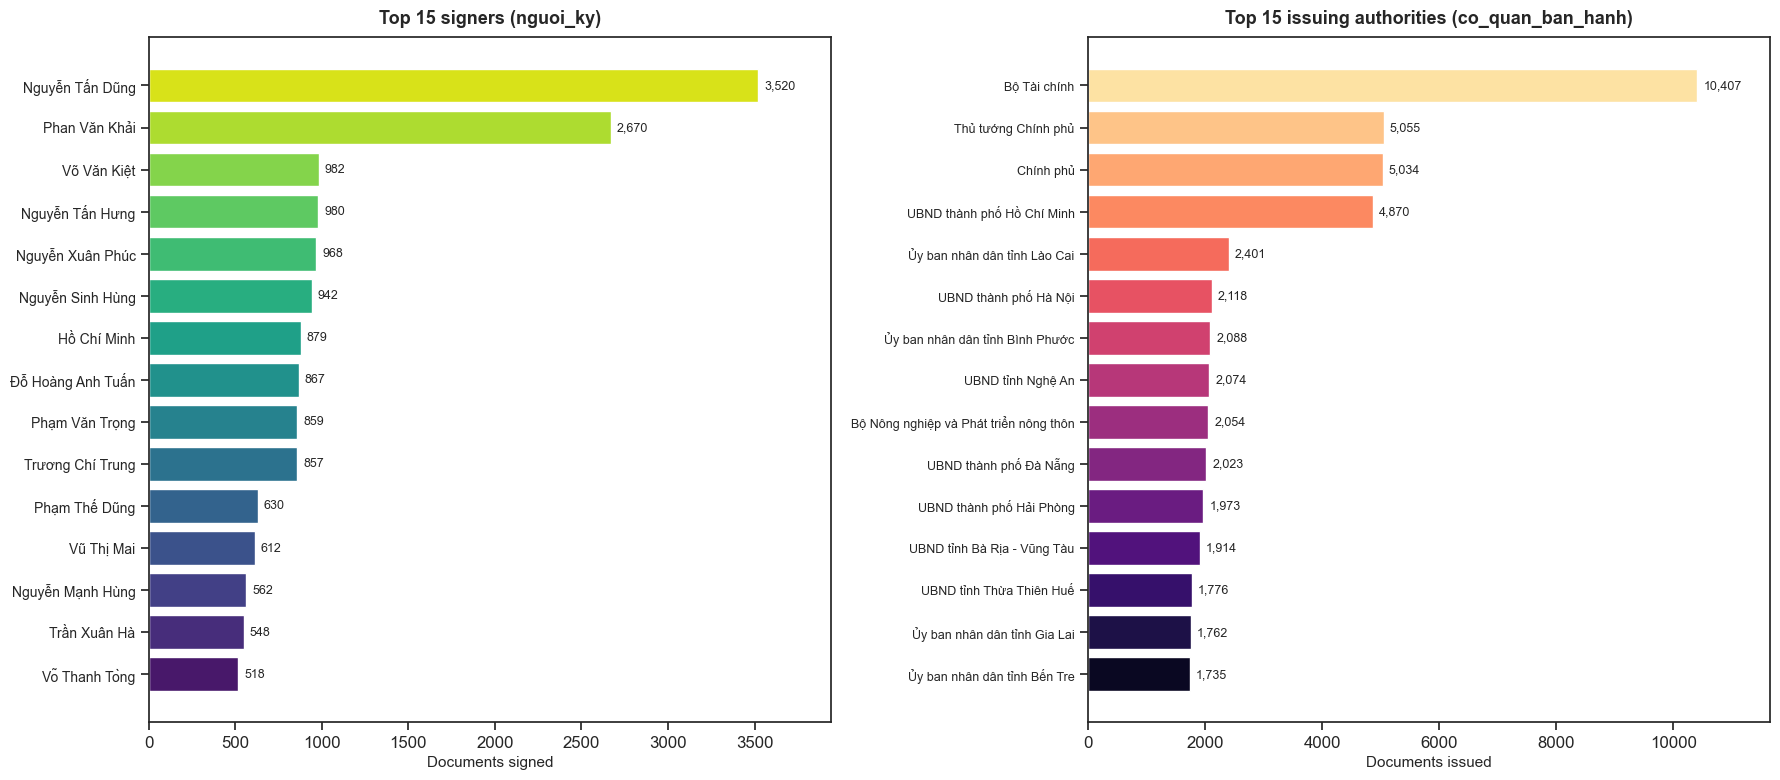

In [23]:
# === Cell 21: Top signers & authorities ===
display(Markdown("### 👤 Top người ký & cơ quan ban hành"))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Top signers
signers = (
    pl.scan_parquet(FILES["data/metadata"])
    .select("nguoi_ky")
    .collect()
    .to_series()
    .drop_nulls()
    .value_counts(sort=True)
    .head(15)
    .to_pandas()
)
signers.columns = ["nguoi_ky", "count"]
signers = signers.sort_values("count", ascending=True)
axes[0].barh(signers["nguoi_ky"], signers["count"],
             color=sns.color_palette("viridis", len(signers)))
axes[0].set_xlabel("Documents signed", fontsize=11)
axes[0].set_title("Top 15 signers (nguoi_ky)", fontsize=13, fontweight="bold", pad=10)
axes[0].tick_params(axis="y", labelsize=10)
max_s = max(signers["count"])
for i, (_, row) in enumerate(signers.iterrows()):
    axes[0].text(row["count"] + max_s * 0.01, i,
                 f'{row["count"]:,}', va="center", fontsize=9)
axes[0].set_xlim(right=max_s * 1.12)

# Top authorities
auths = (
    pl.scan_parquet(FILES["data/metadata"])
    .select("co_quan_ban_hanh")
    .collect()
    .to_series()
    .drop_nulls()
    .value_counts(sort=True)
    .head(15)
    .to_pandas()
)
auths.columns = ["co_quan_ban_hanh", "count"]
auths = auths.sort_values("count", ascending=True)
axes[1].barh(auths["co_quan_ban_hanh"], auths["count"],
             color=sns.color_palette("magma", len(auths)))
axes[1].set_xlabel("Documents issued", fontsize=11)
axes[1].set_title("Top 15 issuing authorities (co_quan_ban_hanh)", fontsize=13, fontweight="bold", pad=10)
axes[1].tick_params(axis="y", labelsize=9)
max_a = max(auths["count"])
for i, (_, row) in enumerate(auths.iterrows()):
    axes[1].text(row["count"] + max_a * 0.01, i,
                 f'{row["count"]:,}', va="center", fontsize=9)
axes[1].set_xlim(right=max_a * 1.12)

plt.tight_layout()
plt.show()

---
## 11. Network – Bậc kết nối trong relationships

### 🔗 Phân tích bậc kết nối (degree) trong relationships

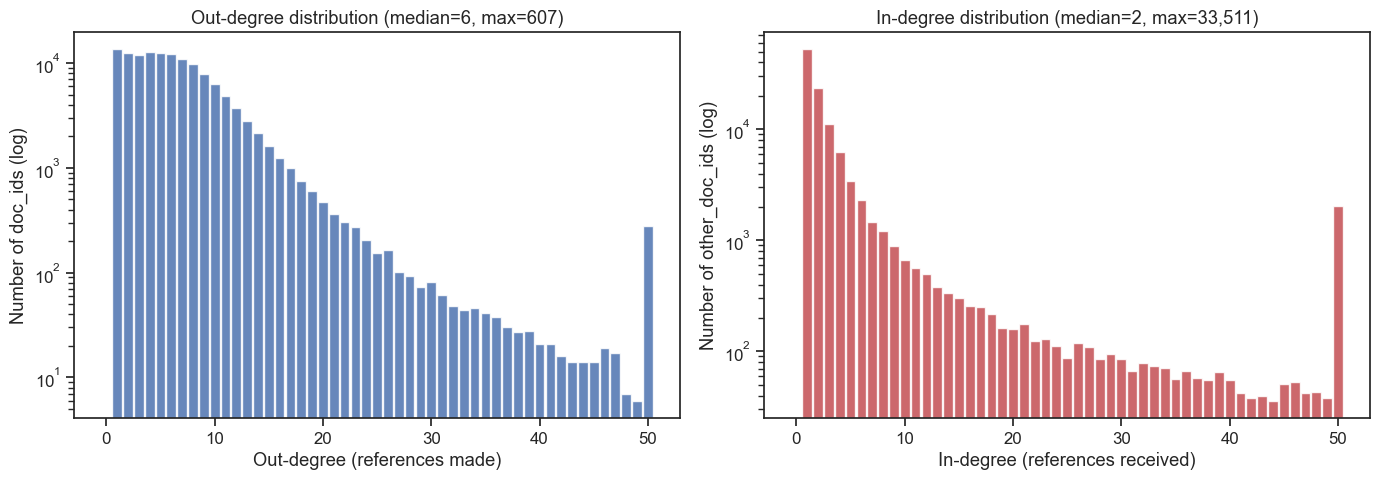

**📌 Top 10 văn bản được tham chiếu nhiều nhất (in-degree):**

id,in_degree,so_ky_hieu,title,loai_van_ban
i64,u32,str,str,str
70819,33511,"""77/2015/QH13""","""Tổ chức chính quyền địa phương""","""Luật"""
20068,26794,"""11/2003/QH11""","""Tổ chức Hội đồng nhân dân và Uỷ ban nhân dân""","""Luật"""
70800,24010,"""80/2015/QH13""","""Ban hành văn bản quy phạm pháp luật""","""Luật"""
139878,17761,"""47/2019/QH14""","""Luật sửa đổi, bổ sung một số điều của Luật Tổ chức Chính phủ và Luật Tổ chức chính quyền địa phương""","""Luật"""
17855,10462,"""31/2004/QH11""","""Ban hành văn bản quy phạm pháp luật của Hội đồng nhân dân, Uỷ ban nhân dân""","""Luật"""
70807,8792,"""83/2015/QH13""","""Ngân sách nhà nước""","""Luật"""
103581,6778,"""34/2016/NĐ-CP""","""Quy định chi tiết một số điều và biện pháp thi hành Luật ban hành văn bản quy phạm pháp luật""","""Nghị định"""
10420,6149,"""Không số""","""Tổ chức Hội đồng nhân dân và Uỷ ban nhân dân""","""Luật"""
22843,5536,"""32/2001/QH10""","""Tổ chức Chính phủ""","""Luật"""


In [24]:
# === Cell 22: Relationship degree distribution ===
display(Markdown("### 🔗 Phân tích bậc kết nối (degree) trong relationships"))

# RAM-safe: compute degree lazily, never load full 3-column df
out_deg = (
    pl.scan_parquet(FILES["data/relationships"])
    .group_by("doc_id").agg(pl.len().alias("out_degree"))
    .collect()
)
in_deg = (
    pl.scan_parquet(FILES["data/relationships"])
    .group_by("other_doc_id").agg(pl.len().alias("in_degree"))
    .collect()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

out_s = out_deg["out_degree"]
out_med, out_max = float(out_s.median()), int(out_s.max())
out_np = out_s.clip(0, 50).to_numpy()
out_bins = np.arange(0, 52)
out_hist, _ = np.histogram(out_np, bins=out_bins)
del out_np
axes[0].bar(out_bins[:-1], out_hist, width=0.9, color="#4C72B0", edgecolor="white", alpha=0.85)
axes[0].set_yscale("log")
axes[0].set_xlabel("Out-degree (references made)")
axes[0].set_ylabel("Number of doc_ids (log)")
axes[0].set_title(f"Out-degree distribution (median={out_med:.0f}, max={out_max:,})")

in_s = in_deg["in_degree"]
in_med, in_max = float(in_s.median()), int(in_s.max())
in_np = in_s.clip(0, 50).to_numpy()
in_hist, _ = np.histogram(in_np, bins=out_bins)
del in_np
axes[1].bar(out_bins[:-1], in_hist, width=0.9, color="#C44E52", edgecolor="white", alpha=0.85)
axes[1].set_yscale("log")
axes[1].set_xlabel("In-degree (references received)")
axes[1].set_ylabel("Number of other_doc_ids (log)")
axes[1].set_title(f"In-degree distribution (median={in_med:.0f}, max={in_max:,})")

plt.tight_layout()
plt.show()

# Top most-referenced documents
display(Markdown("**📌 Top 10 văn bản được tham chiếu nhiều nhất (in-degree):**"))
top_in = (
    in_deg.sort("in_degree", descending=True).head(10)
    .rename({"other_doc_id": "id"})
)
# Join with metadata for context
meta_mini = pl.scan_parquet(FILES["data/metadata"]).select("id", "so_ky_hieu", "title", "loai_van_ban").collect()
top_in_info = top_in.join(meta_mini, on="id", how="left")
display(top_in_info)

---
## 12. Recommendation: data/ vs legacy/

In [25]:
# === Cell 23b: data vs legacy recommendation ===
display(Markdown("### 🧠 Recommendation: Which dataset to use?"))

# Compute comparison metrics
n_data_c = pl.scan_parquet(FILES["data/content"]).select(pl.len()).collect().item()
n_legacy_c = pl.scan_parquet(FILES["legacy/content"]).select(pl.len()).collect().item()
n_data_m = pl.scan_parquet(FILES["data/metadata"]).select(pl.len()).collect().item()
n_legacy_m = pl.scan_parquet(FILES["legacy/metadata"]).select(pl.len()).collect().item()

schema_data_m = pl.scan_parquet(FILES["data/metadata"]).collect_schema()
schema_legacy_m = pl.scan_parquet(FILES["legacy/metadata"]).collect_schema()

recommendation_table = [
    {"Criteria": "Content rows", "data/": f"{n_data_c:,}", "legacy/": f"{n_legacy_c:,}", "Winner": "data (primary)"},
    {"Criteria": "Metadata rows", "data/": f"{n_data_m:,}", "legacy/": f"{n_legacy_m:,}", "Winner": "data (primary)"},
    {"Criteria": "Metadata columns", "data/": str(len(schema_data_m)), "legacy/": str(len(schema_legacy_m)), "Winner": "data (richer)"},
    {"Criteria": "Content format", "data/": "HTML (content_html)", "legacy/": "Plain text (content)", "Winner": "data (strip HTML)"},
    {"Criteria": "Column naming", "data/": "Vietnamese", "legacy/": "English", "Winner": "data (domain-native)"},
    {"Criteria": "Extra metadata", "data/": "7 extra cols", "legacy/": "legal_sectors", "Winner": "data"},
    {"Criteria": "Has relationships?", "data/": "Yes", "legacy/": "No", "Winner": "data (unique)"},
]
display(pl.DataFrame(recommendation_table))

# Dynamic analysis table
display(Markdown(
    f"| Aspect | data/ (Primary) | legacy/ (Supplement) |\n"
    f"|--------|----------------|---------------------|\n"
    f"| Coverage | {n_data_c:,} docs | {n_legacy_c:,} docs (supplement only) |\n"
    f"| Content format | HTML → strip to plain text | Plain text (fallback) |\n"
    f"| Metadata richness | {len(schema_data_m)} cols (primary source) | {len(schema_legacy_m)} cols (supplement `legal_sectors`) |\n"
    f"| Relationships | Available (data/relationships.parquet) | Not available |"
))

### 🧠 Recommendation: Which dataset to use?

Criteria,data/,legacy/,Winner
str,str,str,str
"""Content rows""","""178,665""","""518,235""","""data (primary)"""
"""Metadata rows""","""153,420""","""518,601""","""data (primary)"""
"""Metadata columns""","""17""","""11""","""data (richer)"""
"""Content format""","""HTML (content_html)""","""Plain text (content)""","""data (strip HTML)"""
"""Column naming""","""Vietnamese""","""English""","""data (domain-native)"""
"""Extra metadata""","""7 extra cols""","""legal_sectors""","""data"""
"""Has relationships?""","""Yes""","""No""","""data (unique)"""


| Aspect | data/ (Primary) | legacy/ (Supplement) |
|--------|----------------|---------------------|
| Coverage | 178,665 docs | 518,235 docs (supplement only) |
| Content format | HTML → strip to plain text | Plain text (fallback) |
| Metadata richness | 17 cols (primary source) | 11 cols (supplement `legal_sectors`) |
| Relationships | Available (data/relationships.parquet) | Not available |

**Khuyến nghị:**

1. **Cho RAG**: Dùng `data/content` làm chính (strip HTML → text thuần), kết hợp `data/metadata` cho ngữ cảnh bổ sung
2. **Cho Knowledge Graph**: Dùng `data/relationships` (nguồn duy nhất chứa quan hệ giữa các VB) + `data/metadata` cho node attributes
3. **Chiến lược kết hợp** (khuyến nghị):
   - Lấy `data/` làm tập dữ liệu chính (metadata phong phú hơn, có relationships)
   - Strip HTML từ `data/content` (`content_html`) để tạo plain text cho RAG
   - Dùng `data/relationships` cho các cạnh đồ thị
   - Bổ sung từ `legacy/` khi cần: join cột `legal_sectors` qua ID, hoặc lấy content cho các VB thiếu trong `data/`

### Tóm tắt

**Cấu trúc dữ liệu:**
- 3 bảng chính liên kết qua `id`: **content** <-> **metadata** <-> **relationships**
- 2 bộ dữ liệu: `data/` (bản chính, nội dung **HTML**, metadata phong phú, có relationships) và `legacy/` (bản cũ, **text thuần**, bổ sung)

**Phát hiện chính:**

| # | Phát hiện | Chi tiết |
|---|-----------|----------|
| 1 | **data/ là nguồn chính** | Metadata phong phú hơn (7 cột extra), có relationships – là nguồn duy nhất cho Knowledge Graph |
| 2 | **Format khác nhau** | data/ = **HTML** (`content_html`) → cần strip HTML, legacy/ = **text thuần** (`content`) |
| 3 | **Phân bố loại VB** | Một số loại chiếm đa số (Nghị định, Thông tư...) |
| 4 | **Trạng thái hiệu lực** | ~42% còn hiệu lực, ~52% hết hiệu lực toàn bộ |
| 5 | **Data quality** | `thong_tin_ap_dung` gần như NULL toàn bộ |
| 6 | **content <-> metadata ~1:1** | Hầu hết ID match, rất ít orphan |
| 7 | **Temporal trend** | Số lượng VB tăng mạnh từ ~2000, peak gần đây |
| 8 | **Network** | Phân bố degree theo power law - một số VB gốc được tham chiếu rất nhiều |
| 9 | **Top entities** | Một số người ký & cơ quan ban hành chiếm lượng lớn |

**Dữ liệu phù hợp cho:**
- **RAG** (Retrieval-Augmented Generation) - strip HTML từ `data/content`, kết hợp `data/metadata`
- **Knowledge Graph** - `data/relationships` + `data/metadata` cho nodes & edges
- **Legal NLP** - phân loại, tóm tắt, tìm kiếm ngữ nghĩa
- **Temporal analysis** - xu hướng lập pháp theo thời gian